# 04 · Modèle final et soumissions

La soumission finale combine huit modèles (expérience 15) puis applique trois corrections, dont le lissage par paires (expériences 16–17) : **75.575 en local, 76.030 au score public**. Avant le lissage par paires : 75.966 / 76.298.

| Étape | Ce qui est fait |
|---|---|
| Variables | jeu final du notebook 02 : 57, 73 ou 78 colonnes selon le modèle |
| Modèles | LightGBM, XGBoost, CatBoost, LightGBM DOTS, CatBoost DOTS, CatBoost IPF GL, TabM, HGB |
| Validation | 5 plis × 3 graines (42, 7, 2024), early stopping interne, moyenne des graines |
| Test | arbres réentraînés sur toutes les lignes (itérations = moyenne de validation × 1.2) ; TabM sur 95 %, HGB sur 90 % |
| Combinaison | NNLS global |
| Corrections | lignes jumelles, lissage par groupes, lissage par paires ; coefficients ajustés sur une moitié des données et évalués sur l'autre |

Attention : les scores locaux des corrections ne sont pas une validation de toute la chaîne. Les coefficients sont bien évalués sur des lignes qui n'ont pas servi à les ajuster, mais les modèles de base ne sont pas réentraînés pour ce découpage.

Pour tout refaire depuis zéro : `six_models`, redémarrer, `more_seeds`, redémarrer, `eight_models`, puis `pair_smoothing`.

**Entraînement.** Tous les boutons de `TRAIN` sont à `False` : le notebook relit les résultats sauvegardés dans `artifacts/`, sur CPU, en quelques minutes. Pour refaire une expérience, mettre son bouton à `True` et choisir un runtime **T4 GPU**. Chaque modèle est sauvegardé dès qu'il est entraîné, donc une exécution interrompue reprend où elle s'était arrêtée. Un seul bouton à la fois, et redémarrer le runtime avant de passer au suivant.

In [1]:
"""Compatibilité avec les résultats existants et libellés de présentation.

Les valeurs historiques ci-dessous sont volontairement conservées : elles déterminent
les clés JSON, les noms de caches et leur ordre. Le code de calcul utilise les noms
explicites des constantes ; seules des copies destinées à l’affichage sont traduites.
"""

BLOCK_RECORDING_PRECISION = 'P'
BLOCK_TRAVEL = 'T'
BLOCK_MEET_CONTEXT = 'M'
BLOCK_EXTENDED_MEET_CONTEXT = 'M2'
BLOCK_DIVISION_CONTEXT = 'D'
BLOCK_ATHLETE_HISTORY = 'H'
BLOCK_DOTS_SCALE = 'S'
BLOCK_PROXY_IDENTIFIERS = 'C'
BLOCK_ATHLETE_CAREER = 'H2'
BLOCK_MEET_EXPERIENCE = 'E'
BLOCK_MODEL_SPECIFIC = 'PM'
BLOCK_ATHLETE_PERFORMANCE = 'AS'
BLOCK_MEET_PERFORMANCE = 'MS'
VARIANT_WEIGHT_CLASS_BASELINE = 'F0'
VARIANT_PRECISION_AND_TRAVEL = 'PT'
VARIANT_CONTEXT_COMBINED = 'ALL'
VARIANT_CONTEXT_BASELINE = 'R1'
VARIANT_HISTORY_COMBINED = 'ALL2'
VARIANT_HISTORY_BASELINE = 'R2'
VARIANT_FINAL_FEATURES = 'ALL3'
VARIANT_FINAL_BASELINE = 'R3'
VARIANT_PERFORMANCE_COMBINED = 'ALL4'
CATBOOST_DEPTH8_BASELINE = 'C1'
CATBOOST_DEPTH8_REGULARIZED = 'C2'
CATBOOST_DEPTH6_REGULARIZED = 'C3'
MODEL_LIGHTGBM = 'lgb'
MODEL_XGBOOST = 'xgb'
MODEL_CATBOOST_ABSOLUTE = 'catboost'
MODEL_LIGHTGBM_DOTS = 'lgb_rel'
MODEL_CATBOOST_DOTS = 'cb_rel'
MODEL_CATBOOST_IPF_GL = 'cb_gl'
MODEL_CATBOOST_ALLOMETRIC = 'cb_allo'
MODEL_HISTOGRAM_GRADIENT_BOOSTING = 'hgb'
MODEL_EXTRA_TREES = 'et'
MODEL_RANDOM_FOREST = 'rf'
MATCH_RESIDENCE = 'A0'
MATCH_FEDERATION = 'A1'
MATCH_EQUIPMENT = 'A2'
MATCH_WEIGHT_CLASS = 'A3'
MATCH_MEET = 'M2'
SMOOTHING_EXACT_BIRTHYEAR = 'S0_exact'
SMOOTHING_NEARBY_BIRTHYEAR = 'S1_fuzzy'
SMOOTHING_TEMPORAL = 'S2_decay'
SMOOTHING_COMBINED_LINEAR = 'S3_all_linear'
SMOOTHING_COMBINED_BOOSTING = 'S4_all_gbm'
CACHE_CONTEXT_ABLATION = 'round1'
CACHE_HISTORY_ABLATION = 'round2'
CACHE_CAREER_ABLATION = 'round3'
CACHE_PERFORMANCE_ABLATION = 'round4'
CACHE_SIX_MODEL_ENSEMBLE = 'v1_six_models'
CACHE_EXPANDED_SEED_ENSEMBLE = 'v2_more_seeds'
CACHE_FINAL_ENSEMBLE = 'v4_eight_models'
CACHE_INITIAL_ENSEMBLE = 'baseline_v1'
CACHE_TEN_FOLD_ENSEMBLE = 'baseline_v2'
ENSEMBLE_INITIAL = 'v1'
ENSEMBLE_TEN_FOLD = 'v2'
ENSEMBLE_WITH_HISTOGRAM_BOOSTING = 'v3_plus'
ENSEMBLE_FINAL = 'v4'
MODEL_CATBOOST_DEPTH8_BASELINE = 'catboost_C1'
CONFIG_PURPOSE_CONTEXT_ABLATION = 'feature round 1 (P/T/M blocks); inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_HISTORY_ABLATION = 'feature round 2 on top of 07 ALL; inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_CAREER_ABLATION = 'feature round 3 on top of 09 ALL2; inner 10% early stop, score early-stopped model on outer fold'
MODEL_CATBOOST_DEPTH8_REGULARIZED = 'catboost_C2'
MODEL_CATBOOST_DEPTH6_REGULARIZED = 'catboost_C3'
CONFIG_PURPOSE_MODEL_COMPARISON = 'model zoo on the 07 folds; inner 10% early stop (same split as 07); score on outer fold'

CACHE_CATBOOST_IPF_GL_BASELINE_STEM = 'cb_gl__R3'
CACHE_CATBOOST_IPF_GL_SEED42_STEM = 'cb_gl__s42'
MODEL_CATBOOST_PREFIX = 'cb_'
MODEL_CATBOOST_DOTS_SLOW_LEARNING_RATE = 'cb_rel_lr03'
CONFIG_PURPOSE_SIX_MODEL_ENSEMBLE = 'final ensemble: ALL3 per-model features, 5-fold x seeds, inner 10% early stop, full refit'
SUMMARY_RESIDUAL_SMOOTHING = '+S3'
SUMMARY_FINAL_SMOOTHING = '+ S3 smoothing (cross-fitted coefficients)'
SUMMARY_FINAL_CANDIDATES = '+ HGB + cb_gl (final)'
SUBMISSION_FINAL_BASE_FILENAME = 'submission_final_v4_base.csv'
SUBMISSION_FINAL_FILENAME = 'submission_final_v4_final.csv'

LEGACY_SUMMARY_COMBINED_SMOOTHING = '+ S3 \u5e73\u6ed1\uff08\u4ea4\u53c9\u62df\u5408\uff09'
HISTORY_TEN_FOLD_MATCHING = 'v2 + twins'
HISTORY_WEIGHT_CLASS_MATCHING = '07 F0 + twins'
HISTORY_CONTEXT_REGULARIZED = '07 ALL + C2'
HISTORY_CONTEXT_REGULARIZED_MATCHING = '07 ALL + C2 + twins'
HISTORY_MODEL_STACKING = '08 stack'
HISTORY_STACKING_MATCHING = '08 + twins'
HISTORY_STACKING_RESIDUAL_SMOOTHING = '08 + twins + athlete'
HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING = 'v2 + twins + athlete'
HISTORY_FINAL_FEATURES_MATCHING = '10 ALL3 + twins'
HISTORY_EXACT_BIRTHYEAR_SMOOTHING = '10 + S0'
HISTORY_COMBINED_RESIDUAL_SMOOTHING = '10 + S3'
HISTORY_SIX_MODEL_FOLD_AVERAGE = '11 fold average'
HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE = '13 v3_plus'
HISTORY_FINAL_FEATURES_REFERENCE = '14 R3'
HISTORY_ATHLETE_PERFORMANCE = '14 AS'
HISTORY_FINAL_ENSEMBLE = '15 v4 (final)'


PRESENTATION_LABELS = {
    HISTORY_TEN_FOLD_MATCHING: 'v2 + jumelles',
    HISTORY_WEIGHT_CLASS_MATCHING: 'variables de départ + jumelles',
    HISTORY_CONTEXT_REGULARIZED: 'série 1 + CatBoost régularisé',
    HISTORY_CONTEXT_REGULARIZED_MATCHING: 'série 1 + CatBoost régularisé + jumelles',
    HISTORY_MODEL_STACKING: 'exp. 08 : plus de modèles',
    HISTORY_STACKING_MATCHING: 'exp. 08 + jumelles',
    HISTORY_STACKING_RESIDUAL_SMOOTHING: 'exp. 08 + jumelles + lissage',
    HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING: 'v2 + jumelles + lissage',
    HISTORY_FINAL_FEATURES_MATCHING: 'série 3 + jumelles',
    HISTORY_EXACT_BIRTHYEAR_SMOOTHING: 'série 3 + lissage (même année)',
    HISTORY_COMBINED_RESIDUAL_SMOOTHING: 'série 3 + lissage combiné',
    HISTORY_SIX_MODEL_FOLD_AVERAGE: 'six modèles, moyenne des plis',
    HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE: 'six modèles + HGB',
    HISTORY_FINAL_FEATURES_REFERENCE: 'référence de la série 4',
    HISTORY_ATHLETE_PERFORMANCE: 'niveau du sportif',
    HISTORY_FINAL_ENSEMBLE: 'huit modèles',
    '+ HGB + cb_gl (final, exp. 15)': '+ HGB + CatBoost IPF GL (exp. 15)',
    BLOCK_RECORDING_PRECISION: 'Précision',
    BLOCK_TRAVEL: 'Déplacements',
    BLOCK_MEET_CONTEXT: 'Contexte',
    BLOCK_EXTENDED_MEET_CONTEXT: 'Contexte enrichi',
    BLOCK_DIVISION_CONTEXT: 'Divisions',
    BLOCK_ATHLETE_HISTORY: 'Historique',
    BLOCK_DOTS_SCALE: 'Coefficient DOTS',
    BLOCK_PROXY_IDENTIFIERS: 'Identifiants',
    BLOCK_ATHLETE_CAREER: 'Carrière',
    BLOCK_MEET_EXPERIENCE: 'Expérience du plateau',
    BLOCK_MODEL_SPECIFIC: 'Ajouts par modèle',
    BLOCK_ATHLETE_PERFORMANCE: 'Niveau du sportif',
    BLOCK_MEET_PERFORMANCE: 'Niveau de la compétition',
    VARIANT_WEIGHT_CLASS_BASELINE: 'Départ',
    VARIANT_PRECISION_AND_TRAVEL: 'Précision + déplacements',
    VARIANT_CONTEXT_COMBINED: 'Série 1 complète',
    VARIANT_CONTEXT_BASELINE: 'Référence série 2',
    VARIANT_HISTORY_COMBINED: 'Série 2 retenue',
    VARIANT_HISTORY_BASELINE: 'Référence série 3',
    VARIANT_FINAL_FEATURES: 'Variables finales',
    VARIANT_FINAL_BASELINE: 'Référence série 4',
    VARIANT_PERFORMANCE_COMBINED: 'Niveaux combinés',
    CATBOOST_DEPTH8_BASELINE: 'prof. 8, L2 3',
    CATBOOST_DEPTH8_REGULARIZED: 'prof. 8, L2 10',
    CATBOOST_DEPTH6_REGULARIZED: 'prof. 6, L2 10',
    MODEL_CATBOOST_DOTS: 'CatBoost DOTS',
    MODEL_LIGHTGBM_DOTS: 'LightGBM DOTS',
    MODEL_CATBOOST_IPF_GL: 'CatBoost IPF GL',
    MODEL_CATBOOST_ALLOMETRIC: 'CatBoost allométrique',
    MODEL_LIGHTGBM: 'LightGBM',
    MODEL_XGBOOST: 'XGBoost',
    MODEL_CATBOOST_ABSOLUTE: 'CatBoost',
    MODEL_HISTOGRAM_GRADIENT_BOOSTING: 'HGB',
    MODEL_EXTRA_TREES: 'ExtraTrees',
    MODEL_RANDOM_FOREST: 'Forêt aléatoire',
    MATCH_RESIDENCE: 'Clé 1 :',
    MATCH_FEDERATION: 'Clé 2 :',
    MATCH_EQUIPMENT: 'Clé 3 :',
    MATCH_WEIGHT_CLASS: 'Clé 4 :',
    'S0': 'même année',
    'S1': 'année ±1',
    'S2': 'pondération temporelle',
    'S3': 'lissage combiné',
    'S4': 'lissage LightGBM',
    ENSEMBLE_INITIAL: 'v1',
    ENSEMBLE_TEN_FOLD: 'v2',
    ENSEMBLE_WITH_HISTOGRAM_BOOSTING: 'six modèles + HGB',
    ENSEMBLE_FINAL: 'huit modèles',
    SMOOTHING_EXACT_BIRTHYEAR: 'Même année',
    SMOOTHING_NEARBY_BIRTHYEAR: 'Année ±1',
    SMOOTHING_TEMPORAL: 'Pondération temporelle',
    SMOOTHING_COMBINED_LINEAR: 'Combinaison linéaire',
    SMOOTHING_COMBINED_BOOSTING: 'Combinaison par LightGBM',
}


def presentation_label(value):
    """Traduire un libellé d’expérience sans toucher à sa valeur de calcul."""
    if isinstance(value, tuple):
        return tuple(presentation_label(part) for part in value)
    if not isinstance(value, str):
        return value
    if '|' in value:
        return value
    if value in PRESENTATION_LABELS:
        return PRESENTATION_LABELS[value]
    import re
    if value.endswith(('.csv', '.npz', '.npy', '.json')):
        return value
    keys = [key for key in PRESENTATION_LABELS if key not in (MODEL_EXTRA_TREES, MODEL_RANDOM_FOREST)]
    pattern = r'(?<![A-Za-z0-9_])(' + '|'.join(re.escape(key) for key in sorted(keys, key=len, reverse=True)) + r')(?![A-Za-z0-9_])'
    return re.sub(pattern, lambda match: PRESENTATION_LABELS[match.group()], value)


def presentation_copy(value):
    """Traduire uniquement les libellés de synthèse, sur une copie du tableau."""
    if 'pd' in globals() and isinstance(value, (pd.DataFrame, pd.Series)):
        shown = value.copy(deep=True)
        raw_columns = set(globals().get('RAW_FEATURES', []))
        label_fields = {'model', 'variant', 'tag', 'step', 'method', 'submission',
                        'params_key', 'feature', 'source', 'experiment', 'config',
                        'Ensemble', 'Modèle', 'Expérience', 'Clé'}
        # Un extrait des données conserve toutes ses valeurs et ses catégories.
        if isinstance(shown, pd.DataFrame) and raw_columns.intersection(shown.columns):
            return shown
        if isinstance(shown.index, pd.MultiIndex):
            names = shown.index.names
            shown.index = pd.MultiIndex.from_tuples(
                [tuple(presentation_label(part) if name in label_fields else part
                       for name, part in zip(names, row)) for row in shown.index], names=names)
        elif shown.index.name in label_fields:
            shown.index = shown.index.map(presentation_label)
        if isinstance(shown, pd.DataFrame):
            for column in shown.select_dtypes(include=['object', 'string']):
                if column in label_fields:
                    shown[column] = shown[column].map(presentation_label)
            # Les colonnes de modèles ou de variantes proviennent d’un pivot nommé.
            if shown.columns.name in label_fields:
                shown.columns = shown.columns.map(presentation_label)
        elif shown.name in label_fields and (shown.dtype == object or isinstance(shown.dtype, pd.StringDtype)):
            shown = shown.map(presentation_label)
        return shown
    if isinstance(value, dict):
        return {presentation_label(key): presentation_copy(item) for key, item in value.items()}
    if isinstance(value, list):
        return [presentation_copy(item) for item in value]
    if isinstance(value, tuple):
        return tuple(presentation_copy(item) for item in value)
    return presentation_label(value)


def display(*values, **kwargs):
    """Afficher des libellés explicites sans modifier les tableaux de calcul."""
    return _display(*(presentation_copy(value) for value in values), **kwargs)


def print(*values, **kwargs):
    """Présenter les résumés textuels sans modifier les objets de calcul."""
    import builtins
    return builtins.print(*(presentation_copy(value) for value in values), **kwargs)

In [2]:
TRAIN = {
    'six_models': False,     # Exp. 11 : 6 modèles × 5 plis × 3 graines, refit et nettoyage (~2.5 h GPU)
    'more_seeds': False,     # Exp. 12 : learning rate CatBoost sur cible DOTS, 5 graines de plus, TabM à 95 % (~1 h GPU)
    'eight_models': False,   # Exp. 15 : CatBoost IPF GL et HGB à 3 graines, réentraînement et soumission (~1 h GPU)
    'pair_smoothing': False, # Exp. 16–17 : lissage par paires (CPU, beaucoup de RAM ; demande les résultats de l'exp. 15)
}

In [3]:
# Environnement, chemins et configuration communs aux cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as _display
from scipy.optimize import nnls
from sklearn.model_selection import KFold, train_test_split

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')


def find_project_dir():
    candidates = []
    if os.environ.get('PL_PROJECT_DIR'):
        candidates.append(Path(os.environ['PL_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir PL_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                 # CSV sources, en lecture seule
ARTIFACTS = PROJECT_DIR / 'artifacts'           # Un sous-dossier de résultats par notebook
SEED = 42                                       # Cinq plis fixes : KFold(5, shuffle=True, random_state=42)
N_FOLDS = 5
INNER_STOP_FRACTION = 0.10                      # 10 % du train externe réservé à l’early stopping
MAX_ROUNDS = 20000
MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE]             # Trois modèles pour les ablations, les plus rapides en premier
RUN_ONLY = None                                 # Liste de variantes à exécuter ; None = toutes
KEEP_DELTA = -0.05                              # kg : garder si ΔRMSE moyen ≤ −0.05 et amélioration sur ≥ 4/5 plis
EXPECTED_SHA256 = {'train.csv': '62319814116506fb95a51f1185dbacdb170ab055642ee4c347a30584093d0856',
                   'test.csv': '563c6fa29f9e535740ef1f09b25954f00fbe242c81c0e5a7343dc18aa962ba46'}
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

TRAIN = globals().get('TRAIN', {})              # Pas de bouton dans 01/05 ; 01 entraîne un petit HGB adversarial
if sum(bool(v) for v in TRAIN.values()) > 1:
    raise ValueError('Activer un seul entraînement à la fois ; redémarrer le runtime avant le suivant (variables partagées)')
TRAINING = any(TRAIN.values())


def ensure_training_env():
    """Préparer les dépendances et vérifier le GPU uniquement pour un entraînement."""
    global catboost, lgb, xgb, torch, RealMLP_TD_Regressor, TabM_D_Regressor, PYTABKIT_ERROR, GPU_NAME, VERSIONS
    to_install = []
    try:
        installed_catboost = importlib.metadata.version(MODEL_CATBOOST_ABSOLUTE)
    except importlib.metadata.PackageNotFoundError:
        installed_catboost = None
    if installed_catboost != CATBOOST_VERSION:
        if MODEL_CATBOOST_ABSOLUTE in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà importée ; redémarrer le runtime')
        to_install.append(f'catboost=={CATBOOST_VERSION}')
    try:
        importlib.metadata.version('pytabkit')
    except importlib.metadata.PackageNotFoundError:
        to_install.append('pytabkit')
    if to_install:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
        importlib.invalidate_caches()
    import catboost
    import lightgbm as lgb
    import torch
    import xgboost as xgb
    try:
        from pytabkit import RealMLP_TD_Regressor, TabM_D_Regressor
        PYTABKIT_ERROR = None
    except Exception as exc:                    # Les autres modèles restent disponibles si cet import échoue
        RealMLP_TD_Regressor = TabM_D_Regressor = None
        PYTABKIT_ERROR = repr(exc)
    warnings.filterwarnings('ignore', category=UserWarning)
    if catboost.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version actuelle : {catboost.__version__}')
    if shutil.which('nvidia-smi') is None or not torch.cuda.is_available():
        raise RuntimeError('Un GPU est requis : choisir T4 GPU dans le type de runtime Colab, puis relancer')
    GPU_NAME = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              text=True, capture_output=True, check=False).stdout.strip().splitlines()[0]
    VERSIONS = {MODEL_CATBOOST_ABSOLUTE: catboost.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                'torch': torch.__version__,
                'pytabkit': None if PYTABKIT_ERROR else importlib.metadata.version('pytabkit'),
                'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
    print('GPU         :', GPU_NAME)
    print('Versions    :', VERSIONS)
    if PYTABKIT_ERROR:
        print('pytabkit indisponible, RealMLP / TabM seront ignorés :', PYTABKIT_ERROR)


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
if TRAINING:
    print('Entraînements activés :', [k for k, v in TRAIN.items() if v])

Projet : performances-en-powerlifting
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


## 0. Données, variables et modèles

Les variables et les définitions des modèles ne sont chargées que si un entraînement de modèles est lancé.

In [4]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def rmse(a, b):
    a, b = np.asarray(a, dtype='float64'), np.asarray(b, dtype='float64')
    return float(np.sqrt(np.mean((a - b) ** 2)))


for name, expected in EXPECTED_SHA256.items():
    require(sha256_file(DATA_DIR / name) == expected, f'data/{name} differs from the original input; check the data file')

TARGET = 'TotalKg'
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_FEATURES = [c for c in test.columns if c != 'id']
CAT = [c for c in RAW_FEATURES if c not in RAW_NUM]          # Independent of object / str dtype (pandas 2 and 3).
require(train.shape == (105000, 18) and test.shape == (45000, 17), 'Unexpected data shape')
require(len(CAT) == 13 and all(pd.api.types.is_numeric_dtype(train[c]) for c in RAW_NUM)
        and not any(pd.api.types.is_numeric_dtype(train[c]) for c in CAT), 'Unexpected column groups')
require(not train[RAW_FEATURES].isna().any().any() and not test[RAW_FEATURES].isna().any().any(), 'Unexpected missing values')
y = train[TARGET].to_numpy(dtype='float64')
n_train = len(train)

FOLD_IDS = np.zeros(n_train, dtype=int)
for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(n_train)), start=1):
    FOLD_IDS[valid] = k
print(f'train {train.shape}  test {test.shape}; validation rows per fold: {np.bincount(FOLD_IDS)[1:].tolist()}')
MODEL_TRAINING = any(v for k, v in TRAIN.items() if k != 'pair_smoothing')   # le lissage par paires relit seulement des prédictions

train (105000, 18)  test (45000, 17); validation rows per fold: [21000, 21000, 21000, 21000, 21000]


In [5]:
if MODEL_TRAINING:
    both = pd.concat([train[RAW_FEATURES], test[RAW_FEATURES]], ignore_index=True)

    # Variables initiales et catégorie de poids: weight-class features from ensemble à dix plis et plusieurs graines
    weight_class = pd.to_numeric(both['WeightClassKg'].str.replace('+', '', regex=False), errors='coerce')
    WEIGHT_CLASS_FEATURES = pd.DataFrame({
        'WeightClass_num': weight_class,
        'Is_SHW': both['WeightClassKg'].str.endswith('+').astype('float64'),
        'BW_minus_Class': both['BodyweightKg'] - weight_class,
    })

    # Précision des enregistrements: explicit indicators for recording precision, such as half-years and integers.
    age2 = (both['Age'] * 2).round()
    require(np.allclose(both['Age'] * 2, age2), 'Age is not a multiple of 0.5')
    bw = both['BodyweightKg']
    is_int = np.isclose(bw, bw.round())
    is_1dec = np.isclose(bw * 10, (bw * 10).round())
    is_half = is_1dec & ~is_int & np.isclose((bw * 10).round() % 10, 5)
    pounds = bw / 0.45359237
    RECORDING_PRECISION_FEATURES = pd.DataFrame({
        'age_half': (age2 % 2).astype('float64'),
        'bw_precision': np.select([is_int, is_half, is_1dec], [0.0, 1.0, 2.0], default=3.0),
        'bw_lb_int': (np.abs(pounds - pounds.round()) < 0.015).astype('float64'),
    })

    # Déplacements: travel indicators; NaN when residence is unknown.
    abroad = (both['Country'] != both['MeetCountry']).astype('float64').where(both['Country'] != 'Unknown')
    state_known = ((both['State'] != 'Unknown') & (both['MeetState'] != 'Unknown')
                   & (both['Country'] == both['MeetCountry']))
    other_state = (both['State'] != both['MeetState']).astype('float64').where(state_known)
    TRAVEL_FEATURES = pd.DataFrame({'abroad': abroad, 'other_state': other_state})

    # Contexte de compétition: meet proxy = federation / year / country / state; unlabeled train+test statistics.
    meet = (both['Federation'] + '|' + both['MeetYear'].astype(str) + '|'
            + both['MeetCountry'] + '|' + both['MeetState'])


    def by_meet(values):
        return values.groupby(meet).transform('mean')


    MEET_CONTEXT_FEATURES = pd.DataFrame({
        'meet_n': meet.map(meet.value_counts()).astype('float64'),
        'meet_sexeq_n': both.groupby([meet, both['Sex'], both['Equipment']])['Age'].transform('size').astype('float64'),
        'fed_year_n': both.groupby(['Federation', 'MeetYear'])['Age'].transform('size').astype('float64'),
        'meet_share_other_state': by_meet(other_state),
        'meet_share_abroad': by_meet(abroad),
        'meet_share_age_half': by_meet(RECORDING_PRECISION_FEATURES['age_half']),
        'meet_share_equipped': by_meet((both['Equipment'] != 'Raw').astype('float64')),
        'meet_share_male': by_meet((both['Sex'] == 'M').astype('float64')),
        'meet_mean_age': by_meet(both['Age']),
    })

    CONTEXT_FEATURE_BLOCKS = {BLOCK_RECORDING_PRECISION: RECORDING_PRECISION_FEATURES, BLOCK_TRAVEL: TRAVEL_FEATURES, BLOCK_MEET_CONTEXT: MEET_CONTEXT_FEATURES}
    CONTEXT_VARIANTS = {VARIANT_WEIGHT_CLASS_BASELINE: [], BLOCK_RECORDING_PRECISION: [BLOCK_RECORDING_PRECISION], BLOCK_TRAVEL: [BLOCK_TRAVEL], BLOCK_MEET_CONTEXT: [BLOCK_MEET_CONTEXT], VARIANT_PRECISION_AND_TRAVEL: [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL], VARIANT_CONTEXT_COMBINED: [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT]}
    for name, frame in {VARIANT_WEIGHT_CLASS_BASELINE: WEIGHT_CLASS_FEATURES, **CONTEXT_FEATURE_BLOCKS}.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')

    _CONTEXT_FRAMES = {}


    def context_feature_frames(variant, model):
        """(train, test) features. String categories for CatBoost; category dtype for LGB / XGB, using the unlabeled joint vocabulary."""
        kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
        if (variant, kind) not in _CONTEXT_FRAMES:
            frame = pd.concat([both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [CONTEXT_FEATURE_BLOCKS[b] for b in CONTEXT_VARIANTS[variant]] + [both[CAT]], axis=1)
            require(frame.columns.is_unique, f'{variant} duplicate column names')
            frame[CAT] = frame[CAT].astype(str).astype(object) if kind == 'str' else frame[CAT].astype('category')
            _CONTEXT_FRAMES[(variant, kind)] = (frame.iloc[:n_train].reset_index(drop=True),
                                        frame.iloc[n_train:].reset_index(drop=True))
        return _CONTEXT_FRAMES[(variant, kind)]


    print({v: context_feature_frames(v, MODEL_LIGHTGBM)[0].shape[1] for v in CONTEXT_VARIANTS})
    summary_new = pd.concat([RECORDING_PRECISION_FEATURES, TRAVEL_FEATURES, MEET_CONTEXT_FEATURES], axis=1)
    display(pd.DataFrame({'train_mean': summary_new.iloc[:n_train].mean(), 'test_mean': summary_new.iloc[n_train:].mean(),
                          'nan_share': summary_new.isna().mean()}).round(4))


    _CONTEXT_FRAMES.clear()                     # Release cached feature frames from experiment 07.
    CORE9 = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']
    sex, equipment = both['Sex'], both['Equipment']
    state = both['State'].where(both['State'] != 'Unknown')
    country = both['Country'].where(both['Country'] != 'Unknown')
    national = both['Federation'] + '|' + both['MeetYear'].astype(str) + '|' + both['MeetCountry']


    def counts(key):
        return key.map(key.value_counts()).astype('float64')


    def n_distinct(values, key):
        return values.groupby(key).transform('nunique').astype('float64')


    # Contexte de compétition enrichi: additional meet context; meet and by_meet come from experiment 07.
    EXTENDED_MEET_CONTEXT_FEATURES = pd.DataFrame({
        'meet_n_states': n_distinct(state, meet),
        'meet_n_countries': n_distinct(country, meet),
        'meet_n_wclass': n_distinct(both['WeightClassKg'], meet),
        'meet_share_tested': by_meet((both['Tested'] == 'Yes').astype('float64')),
        'meet_share_raw': by_meet((equipment == 'Raw').astype('float64')),
        'meet_share_multi': by_meet((equipment == 'Multi-ply').astype('float64')),
        'meet_share_bw2dec': by_meet((RECORDING_PRECISION_FEATURES['bw_precision'] == 3).astype('float64')),
        'meet_share_junior': by_meet((both['Age'] < 24).astype('float64')),
        'meet_share_master': by_meet((both['Age'] >= 40).astype('float64')),
        'meet_age_std': both['Age'].groupby(meet).transform('std'),
        'meet_sex_bw_mean': both['BodyweightKg'].groupby([meet, sex]).transform('mean'),
        'nat_n': counts(national),
        'nat_n_meetstates': n_distinct(both['MeetState'], national),
        'nat_n_states': n_distinct(state, national),
    })

    # Effectifs et rangs des divisions: division context
    division = meet + '|' + sex + '|' + equipment + '|' + both['WeightClassKg']
    age_division = meet + '|' + sex + '|' + equipment + '|' + both['AgeClass']
    exact_key = pd.Series(pd.util.hash_pandas_object(both[RAW_FEATURES], index=False).to_numpy())
    core_key = pd.Series(pd.util.hash_pandas_object(both[CORE9], index=False).to_numpy())
    DIVISION_FEATURES = pd.DataFrame({
        'div_n': counts(division),
        'div_bw_rank': both['BodyweightKg'].groupby(division).rank(pct=True),
        'div_age_rank': both['Age'].groupby(division).rank(pct=True),
        'agediv_n': counts(age_division),
        'dup_exact_n': counts(exact_key) - 1,
        'dup_core_n': counts(core_key) - 1,
    })

    # Historique approché du sportif: athlete proxy history from floor(MeetYear - Age); birth-year estimates may differ by one.
    valid = (both['Country'] != 'Unknown').to_numpy()
    birth = np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int).astype(str)
    athlete = sex + '|' + both['Country'] + '|' + both['State'] + '|' + both['Federation'] + '|' + birth
    athlete0 = sex + '|' + both['Country'] + '|' + both['State'] + '|' + birth
    year = both['MeetYear'].astype('float64')
    ATHLETE_HISTORY_FEATURES = pd.DataFrame({
        'ath_n': counts(athlete),
        'ath_n_years': n_distinct(year, athlete),
        'ath_years_since_first': year - year.groupby(athlete).transform('min'),
        'ath_years_to_last': year.groupby(athlete).transform('max') - year,
        'ath_n_equipment': n_distinct(equipment, athlete),
        'ath_bw_delta': both['BodyweightKg'] - both['BodyweightKg'].groupby(athlete).transform('mean'),
        'ath0_n': counts(athlete0),
        'ath0_n_feds': n_distinct(both['Federation'], athlete0),
    })
    ATHLETE_HISTORY_FEATURES.loc[~valid] = np.nan


    # Facteur DOTS: DOTS scale (TotalKg = DOTS score * dots_scale)
    def dots_scale(sex_values, bw_values):
        s = np.asarray(sex_values).astype(str)
        bw = np.asarray(bw_values, dtype='float64')
        m, f = np.clip(bw, 40, 210), np.clip(bw, 40, 150)
        poly_m = -1.0930e-6 * m**4 + 7.391293e-4 * m**3 - 0.1918759221 * m**2 + 24.0900756 * m - 307.75076
        poly_f = -1.0706e-6 * f**4 + 5.158568e-4 * f**3 - 0.1126655495 * f**2 + 13.6175032 * f - 57.96288
        return np.where(s == 'M', poly_m, np.where(s == 'F', poly_f, 0.5 * (poly_m + poly_f))) / 500.0


    DOTS_SCALE_FEATURE = pd.DataFrame({'dots_scale': dots_scale(sex, both['BodyweightKg'])})

    # Identifiants approchés: high-cardinality IDs for CatBoost ordered target statistics.
    PROXY_IDENTIFIER_FEATURES = pd.DataFrame({'meet_id': meet, 'athlete_id': (athlete + '|' + equipment).where(valid, 'unknown')})

    HISTORY_FEATURE_BLOCKS = {BLOCK_EXTENDED_MEET_CONTEXT: EXTENDED_MEET_CONTEXT_FEATURES, BLOCK_DIVISION_CONTEXT: DIVISION_FEATURES, BLOCK_ATHLETE_HISTORY: ATHLETE_HISTORY_FEATURES, BLOCK_DOTS_SCALE: DOTS_SCALE_FEATURE}
    CATBOOST_CATEGORY_BLOCKS = {BLOCK_PROXY_IDENTIFIERS: PROXY_IDENTIFIER_FEATURES}
    for name, frame in {**HISTORY_FEATURE_BLOCKS, **CATBOOST_CATEGORY_BLOCKS}.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
    for name, frame in HISTORY_FEATURE_BLOCKS.items():
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')
    require(DOTS_SCALE_FEATURE['dots_scale'].min() > 0.3, 'Invalid DOTS scale')

    CONTEXT_BASE_BLOCKS = [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT]
    HISTORY_VARIANTS = {VARIANT_CONTEXT_BASELINE: [], BLOCK_EXTENDED_MEET_CONTEXT: [BLOCK_EXTENDED_MEET_CONTEXT], BLOCK_DIVISION_CONTEXT: [BLOCK_DIVISION_CONTEXT], BLOCK_ATHLETE_HISTORY: [BLOCK_ATHLETE_HISTORY], BLOCK_DOTS_SCALE: [BLOCK_DOTS_SCALE], BLOCK_PROXY_IDENTIFIERS: [BLOCK_PROXY_IDENTIFIERS]}
    MODELS_FOR = {BLOCK_PROXY_IDENTIFIERS: [MODEL_CATBOOST_ABSOLUTE]}      # Identifiants approchés changes CatBoost only; retain Référence avec contexte for LightGBM / XGBoost in the blend.
    SCREEN = [v for v in HISTORY_VARIANTS if RUN_ONLY is None or v in RUN_ONLY or v == VARIANT_CONTEXT_BASELINE]
    _HISTORY_FRAMES = {}


    def models_for(variant):
        return MODELS_FOR.get(variant, MODELS)


    def history_feature_frames(variant, model):
        """Retourner train, test et colonnes catégorielles : variables initiales, catégorie de poids, précision, déplacements et contexte ; les identifiants approchés sont ajoutés à CatBoost uniquement."""
        blocks = HISTORY_VARIANTS[variant]
        kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
        key = (tuple(blocks), kind)
        if key not in _HISTORY_FRAMES:
            nums = ([both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [CONTEXT_FEATURE_BLOCKS[b] for b in CONTEXT_BASE_BLOCKS]
                    + [HISTORY_FEATURE_BLOCKS[b] for b in blocks if b in HISTORY_FEATURE_BLOCKS])
            cats = [both[CAT]] + ([CATBOOST_CATEGORY_BLOCKS[b] for b in blocks if b in CATBOOST_CATEGORY_BLOCKS] if kind == 'str' else [])
            frame = pd.concat(nums + cats, axis=1)
            require(frame.columns.is_unique, f'{variant} duplicate column names')
            cat_cols = [c for part in cats for c in part.columns]
            if kind == 'str':
                frame[cat_cols] = frame[cat_cols].astype(str).astype(object)
            else:
                frame[cat_cols] = frame[cat_cols].astype('category')
            _HISTORY_FRAMES[key] = (frame.iloc[:n_train].reset_index(drop=True),
                             frame.iloc[n_train:].reset_index(drop=True), cat_cols)
        return _HISTORY_FRAMES[key]


    new_cols = pd.concat([EXTENDED_MEET_CONTEXT_FEATURES, DIVISION_FEATURES, ATHLETE_HISTORY_FEATURES, DOTS_SCALE_FEATURE], axis=1)
    display(pd.DataFrame({'train_mean': new_cols.iloc[:n_train].mean(), 'test_mean': new_cols.iloc[n_train:].mean(),
                          'nan_share': new_cols.isna().mean()}).round(4))
    print('Cardinality of C: ', {c: int(PROXY_IDENTIFIER_FEATURES[c].nunique()) for c in PROXY_IDENTIFIER_FEATURES.columns})
    print('Columns by variant (LightGBM / XGBoost): ', {v: history_feature_frames(v, MODEL_LIGHTGBM)[0].shape[1] for v in HISTORY_VARIANTS if v != BLOCK_PROXY_IDENTIFIERS},
          '|CatBoost C: ', history_feature_frames(BLOCK_PROXY_IDENTIFIERS, MODEL_CATBOOST_ABSOLUTE)[0].shape[1])


    _HISTORY_FRAMES.clear()                    # Release cached feature frames from experiment 09.
    birth_num = np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int)


    def fuzzy_count(prefix_key):
        """Count rows with the same prefix and birth years b-1, b, b+1."""
        exact = prefix_key + '|' + birth_num.astype(str)
        table = exact.value_counts()
        total = exact.map(table).astype('float64')
        for d in (-1, 1):
            total = total + (prefix_key + '|' + (birth_num + d).astype(str)).map(table).fillna(0)
        return total


    # Carrière approchée du sportif: career features; athlete/valid and Contexte de compétition enrichi from 09, Contexte de compétition/Déplacements from 07.
    bw = both['BodyweightKg']
    ATHLETE_CAREER_FEATURES = pd.DataFrame({
        'ath_max_meet_states': EXTENDED_MEET_CONTEXT_FEATURES['meet_n_states'].groupby(athlete).transform('max'),
        'ath_mean_meet_states': EXTENDED_MEET_CONTEXT_FEATURES['meet_n_states'].groupby(athlete).transform('mean'),
        'ath_max_meet_n': MEET_CONTEXT_FEATURES['meet_n'].groupby(athlete).transform('max'),
        'ath_max_nat_states': EXTENDED_MEET_CONTEXT_FEATURES['nat_n_states'].groupby(athlete).transform('max'),
        'ath_ever_abroad': TRAVEL_FEATURES['abroad'].groupby(athlete).transform('max'),
        'ath_n_wclass': n_distinct(both['WeightClassKg'], athlete),
        'ath_bw_range': bw.groupby(athlete).transform('max') - bw.groupby(athlete).transform('min'),
        'ath_first_age': both['Age'].groupby(athlete).transform('min'),
        'ath_n_same_year': both.groupby([athlete, both['MeetYear']])['Age'].transform('size').astype('float64'),
        'ath_share_tested': (both['Tested'] == 'Yes').astype('float64').groupby(athlete).transform('mean'),
        'ath_n_fuzzy': fuzzy_count(sex + '|' + both['Country'] + '|' + both['State'] + '|' + both['Federation']),
        'ath0_n_fuzzy': fuzzy_count(sex + '|' + both['Country'] + '|' + both['State']),
    })
    ATHLETE_CAREER_FEATURES.loc[~valid] = np.nan

    # Expérience du plateau: experience profile of a meet
    experience = ATHLETE_HISTORY_FEATURES['ath_years_since_first']
    MEET_EXPERIENCE_FEATURES = pd.DataFrame({
        'meet_mean_ath_n': ATHLETE_HISTORY_FEATURES['ath_n'].groupby(meet).transform('mean'),
        'meet_mean_ath_exp': experience.groupby(meet).transform('mean'),
        'meet_share_veterans': (experience >= 3).astype('float64').where(experience.notna()).groupby(meet).transform('mean'),
        'meet_share_newcomers': (ATHLETE_HISTORY_FEATURES['ath_n'] == 1).astype('float64').where(ATHLETE_HISTORY_FEATURES['ath_n'].notna()).groupby(meet).transform('mean'),
    })

    CAREER_FEATURE_BLOCKS = {BLOCK_ATHLETE_CAREER: ATHLETE_CAREER_FEATURES, BLOCK_MEET_EXPERIENCE: MEET_EXPERIENCE_FEATURES}
    for name, frame in CAREER_FEATURE_BLOCKS.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')
    NUMERIC_BLOCKS = {**CONTEXT_FEATURE_BLOCKS, **HISTORY_FEATURE_BLOCKS, **CAREER_FEATURE_BLOCKS}          # Précision des enregistrements Déplacements Contexte de compétition (07), Contexte de compétition enrichi Effectifs et rangs des divisions Historique approché du sportif Facteur DOTS (09), Carrière approchée du sportif Expérience du plateau (this round)
    HISTORY_BASE_BLOCKS = [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT, BLOCK_ATHLETE_HISTORY]                          # Contexte et historique du sportif from experiment 09
    MODEL_SPECIFIC_BLOCKS = {MODEL_LIGHTGBM: [], MODEL_XGBOOST: [BLOCK_EXTENDED_MEET_CONTEXT, BLOCK_DOTS_SCALE, BLOCK_DIVISION_CONTEXT], MODEL_CATBOOST_ABSOLUTE: [BLOCK_EXTENDED_MEET_CONTEXT, BLOCK_PROXY_IDENTIFIERS]}   # Ajouts propres à chaque modèle: blocks selected separately by model in experiment 09.
    CAREER_VARIANTS = {VARIANT_HISTORY_BASELINE: [], BLOCK_ATHLETE_CAREER: [BLOCK_ATHLETE_CAREER], BLOCK_MEET_EXPERIENCE: [BLOCK_MEET_EXPERIENCE], BLOCK_MODEL_SPECIFIC: [BLOCK_MODEL_SPECIFIC]}
    SCREEN3 = [v for v in CAREER_VARIANTS if RUN_ONLY is None or v in RUN_ONLY or v == VARIANT_HISTORY_BASELINE]
    _CAREER_FRAMES = {}


    def feature_blocks_for_model(variant, model):
        out = list(HISTORY_BASE_BLOCKS)
        for b in CAREER_VARIANTS[variant]:
            out += MODEL_SPECIFIC_BLOCKS[model] if b == BLOCK_MODEL_SPECIFIC else [b]
        return out


    def runs(model, variant):
        """Entraîner seulement si les variables diffèrent de la référence avec historique ; les ajouts propres au modèle laissent LightGBM inchangé."""
        return variant == VARIANT_HISTORY_BASELINE or feature_blocks_for_model(variant, model) != feature_blocks_for_model(VARIANT_HISTORY_BASELINE, model)


    def career_feature_frames(variant, model):
        """(train, test, categorical columns)."""
        blocks = feature_blocks_for_model(variant, model)
        kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
        key = (tuple(blocks), kind)
        if key not in _CAREER_FRAMES:
            nums = [both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [NUMERIC_BLOCKS[b] for b in blocks if b in NUMERIC_BLOCKS]
            cats = [both[CAT]] + ([CATBOOST_CATEGORY_BLOCKS[b] for b in blocks if b in CATBOOST_CATEGORY_BLOCKS] if kind == 'str' else [])
            frame = pd.concat(nums + cats, axis=1)
            require(frame.columns.is_unique, f'{variant} {model} duplicate column names')
            cat_cols = [c for part in cats for c in part.columns]
            if kind == 'str':
                frame[cat_cols] = frame[cat_cols].astype(str).astype(object)
            else:
                frame[cat_cols] = frame[cat_cols].astype('category')
            _CAREER_FRAMES[key] = (frame.iloc[:n_train].reset_index(drop=True),
                             frame.iloc[n_train:].reset_index(drop=True), cat_cols)
        return _CAREER_FRAMES[key]


    new_cols = pd.concat([ATHLETE_CAREER_FEATURES, MEET_EXPERIENCE_FEATURES], axis=1)
    display(pd.DataFrame({'train_mean': new_cols.iloc[:n_train].mean(), 'test_mean': new_cols.iloc[n_train:].mean(),
                          'nan_share': new_cols.isna().mean()}).round(4))
    print({f'{v}/{m}': career_feature_frames(v, m)[0].shape[1] for v in CAREER_VARIANTS for m in MODELS if runs(m, v)})
else:
    print("Pas d’entraînement de modèles : lecture des résultats, sans recalcul des variables.")

Pas d’entraînement de modèles : lecture des résultats, sans recalcul des variables.


In [6]:
if MODEL_TRAINING:
    ensure_training_env()
    SEEDS = [42, 7, 2024]                      # Chaque graine change les plis, l’early stopping et l’aléa du modèle
    FINAL_MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS, 'tabm']   # Modèles rapides en premier dans chaque pli
    FULL_REFIT = True                          # Refit des arbres sur tout le train
    REFIT_FACTOR = 1.2                         # Itérations de refit = moyenne CV × 1.2 (environ 39 % de données en plus)

    # ---- Final features: Variables finales par modèle from experiment 10----
    _CAREER_FRAMES.clear()
    CAREER_VARIANTS[VARIANT_FINAL_FEATURES] = [BLOCK_ATHLETE_CAREER, BLOCK_MEET_EXPERIENCE, BLOCK_MODEL_SPECIFIC]
    FAMILY = {MODEL_LIGHTGBM: MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS: MODEL_LIGHTGBM, 'tabm': MODEL_LIGHTGBM, MODEL_XGBOOST: MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE: MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS: MODEL_CATBOOST_ABSOLUTE}
    FRAMES = {m: career_feature_frames(VARIANT_FINAL_FEATURES, FAMILY[m]) for m in FINAL_MODELS}
    for m, (Xtr_m, Xte_m, cats_m) in FRAMES.items():
        print(f'{m:9s} {Xtr_m.shape[1]} columns ({len(cats_m)} categorical), blocks: {feature_blocks_for_model(VARIANT_FINAL_FEATURES, FAMILY[m])}')


    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)
    XGB_PARAMS = dict(learning_rate=0.03, max_depth=8, min_child_weight=10.0, subsample=0.8, colsample_bytree=0.7,
                      reg_lambda=1.0, tree_method='hist', device='cuda', enable_categorical=True,
                      max_cat_to_onehot=1, eval_metric='rmse')
    CB_PARAMS = dict(learning_rate=0.05, depth=8, l2_leaf_reg=10.0, bootstrap_type='Bernoulli', subsample=0.8,
                     border_count=128)
    TABM_PARAMS = dict(device='cuda', n_cv=1, n_refit=0, verbosity=0, num_emb_type='pwl')
    TABM_FALLBACK = dict(device='cuda', n_cv=1, n_refit=0, verbosity=0)
    PATIENCE = {MODEL_LIGHTGBM: 200, MODEL_LIGHTGBM_DOTS: 200, MODEL_XGBOOST: 200, MODEL_CATBOOST_ABSOLUTE: 300, MODEL_CATBOOST_DOTS: 300}
    GBDT = [m for m in FINAL_MODELS if m != 'tabm']

    SCALE = dots_scale(train['Sex'], train['BodyweightKg'])           # dots_scale is defined in the experiment 09 features.
    SCALE_TEST = dots_scale(test['Sex'], test['BodyweightKg'])
    require(min(SCALE.min(), SCALE_TEST.min()) > 0.3, 'Invalid DOTS scale')

    X_NN, XT_NN, CATS_NN = FRAMES['tabm']
    NUM_NN = [c for c in X_NN.columns if c not in CATS_NN]
    NAN_NN = [c for c in NUM_NN if X_NN[c].isna().any() or XT_NN[c].isna().any()]


    def target_and_weight(model, rows):
        if model.endswith('_rel'):
            return y[rows] / SCALE[rows], SCALE[rows] ** 2       # Relative error * scale = error in kg
        return y[rows], None


    def gbdt_fit(model, seed, Xa, ya, wa, Xs=None, ys=None, ws=None, rounds=MAX_ROUNDS):
        """No early stopping when Xs is None. Return (model, best iteration)."""
        cats = FRAMES[model][2]
        if model in (MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS):
            m = lgb.LGBMRegressor(n_estimators=rounds, random_state=seed, n_jobs=-1, **LGB_PARAMS)
            if Xs is None:
                m.fit(Xa, ya, sample_weight=wa)
                return m, rounds
            m.fit(Xa, ya, sample_weight=wa, eval_set=[(Xs, ys)], eval_sample_weight=None if ws is None else [ws],
                  callbacks=[lgb.early_stopping(PATIENCE[model], verbose=False)])
            return m, int(m.best_iteration_ or rounds)
        if model == MODEL_XGBOOST:
            if Xs is None:
                m = xgb.XGBRegressor(n_estimators=rounds, random_state=seed, **XGB_PARAMS)
                m.fit(Xa, ya, verbose=False)
                return m, rounds
            m = xgb.XGBRegressor(n_estimators=rounds, random_state=seed, early_stopping_rounds=PATIENCE[MODEL_XGBOOST],
                                 **XGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], verbose=False)
            return m, int(m.best_iteration) + 1
        common = dict(iterations=rounds, loss_function='RMSE', eval_metric='RMSE', random_seed=seed, verbose=0,
                      task_type='GPU', devices='0', allow_writing_files=False, **CB_PARAMS)
        if Xs is None:
            m = catboost.CatBoostRegressor(**common)
            m.fit(catboost.Pool(Xa, ya, cat_features=cats, weight=wa))
            return m, rounds
        m = catboost.CatBoostRegressor(od_type='Iter', od_wait=PATIENCE[model], **common)
        m.fit(catboost.Pool(Xa, ya, cat_features=cats, weight=wa),
              eval_set=catboost.Pool(Xs, ys, cat_features=cats, weight=ws), use_best_model=True)
        return m, int(m.get_best_iteration()) + 1


    def gbdt_predict(model, m, best, X):
        if model in (MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS):
            return m.predict(X, num_iteration=best)
        if model == MODEL_XGBOOST:
            return m.predict(X, iteration_range=(0, best))
        return m.predict(X)


    def nn_frames(*frames):
        """Impute from the first fitting frame and add missingness flags; keep category dtype."""
        median = frames[0][NUM_NN].median()
        out = []
        for frame in frames:
            z = frame.copy()
            for c in NAN_NN:
                z[f'{c}_isna'] = z[c].isna().astype('float64')
            z[NUM_NN] = z[NUM_NN].fillna(median).fillna(0.0)
            out.append(z.reset_index(drop=True))
        return out


    def tabm_fit_predict(seed, a, s, v, Xt, overrides=None):
        require(TabM_D_Regressor is not None, f'pytabkit unavailable: {PYTABKIT_ERROR}')
        params = dict(TABM_PARAMS, random_state=seed, **(overrides or {}))
        unknown = set(params) - set(inspect.signature(TabM_D_Regressor.__init__).parameters)
        require(not unknown, f'TabM does not support parameters {sorted(unknown)}')
        Za, Zs, Zv, Zt = nn_frames(X_NN.iloc[a], X_NN.iloc[s], X_NN.iloc[v], Xt)
        mu, sd = y[a].mean(), y[a].std()
        m = TabM_D_Regressor(**params)
        m.fit(Za, (y[a] - mu) / sd, Zs, (y[s] - mu) / sd, cat_col_names=[c for c in Za.columns if c in CATS_NN])
        p_val = np.asarray(m.predict(Zv), dtype='float64').reshape(-1) * sd + mu
        p_test = np.asarray(m.predict(Zt), dtype='float64').reshape(-1) * sd + mu
        del m
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test


    def fit_fold(model, seed, a, s, v, test_rows=None, rounds=MAX_ROUNDS, overrides=None):
        """a / s / v: inner fitting / early-stopping / outer validation indices. Return (validation predictions, test predictions, best iteration or None)."""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        if model == 'tabm':
            p_val, p_test = tabm_fit_predict(seed, a, s, v, Xt, overrides)
            return p_val, p_test, None
        ya, wa = target_and_weight(model, a)
        ys, ws = target_and_weight(model, s)
        if wa is not None:
            norm = wa.mean()
            wa, ws = wa / norm, ws / norm
        m, best = gbdt_fit(model, seed, Xtr.iloc[a], ya, wa, Xtr.iloc[s], ys, ws, rounds)
        p_val, p_test = gbdt_predict(model, m, best, Xtr.iloc[v]), gbdt_predict(model, m, best, Xt)
        if model.endswith('_rel'):
            p_val, p_test = np.asarray(p_val) * SCALE[v], np.asarray(p_test) * scale_t
        return np.asarray(p_val, dtype='float64'), np.asarray(p_test, dtype='float64'), best


    def fit_full(model, seed, rounds, test_rows=None):
        """Fit all rows for a fixed number of iterations; return test predictions."""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        rows = np.arange(n_train)
        ya, wa = target_and_weight(model, rows)
        if wa is not None:
            wa = wa / wa.mean()
        m, _ = gbdt_fit(model, seed, Xtr, ya, wa, rounds=rounds)
        p_test = gbdt_predict(model, m, rounds, Xt)
        if model.endswith('_rel'):
            p_test = np.asarray(p_test) * scale_t
        return np.asarray(p_test, dtype='float64')
else:
    print("Pas d’entraînement de modèles : définitions inutiles.")

Pas d’entraînement de modèles : définitions inutiles.


In [7]:
# Lecture des summary_*.csv et prédictions de plis ; aucun entraînement
def read_summary(path, index_col=0):
    path = Path(path)
    if not path.is_file():
        print(f'Fichier absent : {path.relative_to(PROJECT_DIR)} ; synchroniser artifacts/ depuis Drive ou activer l’entraînement associé')
        return None
    table = pd.read_csv(path, index_col=index_col)
    # Traduire les anciens libellés en mémoire, sans modifier les caches CSV.
    label_map = {
        LEGACY_SUMMARY_COMBINED_SMOOTHING: '+ lissage combiné des résidus (coefficients croisés)',
        '+ \u53cc\u80de\u80ce\uff08\u4ea4\u53c9\u62df\u5408\uff09': '+ jumeaux (cross-fitting)',
        '+\u53cc\u80de\u80ce': '+matched',
        '08 \u4e94\u6298\u5806\u53e0\uff08global_nnls\uff09': '08 stacking, cinq plis (global_nnls)',
        '3 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '3 refits',
        '5 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '5 refits',
        '8 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '8 refits',
        'v2\uff0810 \u6298 \xd7 \u79cd\u5b50\uff0cNNLS\uff09': 'v2 (10 plis × graines, NNLS)',
        '\u500d\u6570': 'ratio',
        '\u540c\u4e00\u56fd\u5bb6': 'Même pays',
        '\u540c\u4e00\u573a\u6bd4\u8d5b': 'Même compétition',
        '\u540c\u4e00\u6bd4\u8d5b\u5e74\u4efd': 'Même année de compétition',
        '\u540c\u4e00\u8054\u76df': 'Même fédération',
        '\u6309 id \u6392\u5e8f': 'sorted_by_id',
        '\u6765\u6e90': 'source',
        '\u76f8\u90bb\u4e24\u884c': 'adjacent_rows',
        '\u878d\u5408\uff08\u5d4c\u5957\uff09': 'Ensemble (RMSE locale)',
        '\u968f\u673a\u987a\u5e8f': 'random_order',
    }
    table = table.rename(columns=label_map, index=label_map)
    for column in table.select_dtypes(include=['object', 'string']):
        table[column] = table[column].map(lambda value: label_map.get(value, value))
    return table


def show(table, columns=None, digits=3):
    if table is not None:
        shown = table if columns is None else table[[c for c in columns if c in table.columns]]
        display(shown.round(digits))


def plot_fold_deltas(table, baseline, title):
    """Comparaison appariée : barre = ΔRMSE moyen, points = plis, pointillé = seuil −0.05."""
    if table is None:
        return
    rows = table.drop(index=baseline, errors='ignore').sort_values('mean_delta', ascending=False)
    folds = rows[[f'd_fold{k}' for k in range(1, N_FOLDS + 1)]].to_numpy(dtype='float64')
    colours = ['#4c72b0' if v <= KEEP_DELTA else '#c44e52' if v > 0 else '#999999' for v in rows['mean_delta']]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(rows) + 1.6))
    ax.barh(range(len(rows)), rows['mean_delta'], color=colours)
    for i in range(len(rows)):
        ax.scatter(folds[i], np.full(folds.shape[1], i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.axvline(KEEP_DELTA, color='#4c72b0', lw=0.8, ls='--')
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([presentation_label(value) for value in rows.index.tolist()])
    ax.set_xlabel(f'Écart de RMSE par rapport à {presentation_label(baseline)} (kg) ; barres : moyenne, points : plis')
    ax.set_title(presentation_label(title))
    plt.tight_layout()
    plt.show()


def read_folds(directory, stem):
    """Charger OOF et test moyen des cinq plis ; retourner None si un pli manque."""
    oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
    for k in range(1, N_FOLDS + 1):
        path = Path(directory) / f'{stem}__fold{k}.npz'
        if not path.is_file():
            return None
        saved = np.load(path)
        oof[saved['valid_idx']] = saved['val']
        test_pred += saved['test'] / N_FOLDS
    return (oof, test_pred) if not np.isnan(oof).any() else None

## 1. Six modèles × cinq plis × trois graines (expérience 11)

LightGBM et XGBoost gardent les paramètres de v2, CatBoost le réglage choisi dans le notebook 03. Pour les modèles DOTS : cible = total ÷ coefficient, poids = coefficient², puis retour en kg. TabM utilise les paramètres par défaut de pytabkit avec les embeddings linéaires par morceaux ; les valeurs manquantes sont remplacées par la médiane avec un indicateur, et la cible est standardisée.

Trois façons de prédire le test sont comparées : la moyenne des 15 modèles de plis, des arbres réentraînés sur toutes les lignes (un par graine), ou la moyenne des deux. Le même bouton lance l'essai de nettoyage du notebook 05.

In [8]:
if TRAIN['six_models']:
    ensure_training_env()
    # Ensemble à six candidats et trois graines ; ancien dossier : artifacts/final_v1
    OUTPUT_DIR = ARTIFACTS / '04_final_model' / CACHE_SIX_MODEL_ENSEMBLE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    RUN_CLEANING_TEST = True                   # Essai de nettoyage présenté dans 05
    # ---- Smoke check on 3,000 rows, then 30-iteration full refit for tree models. ----
    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    failed = {}
    for model in FINAL_MODELS:
        attempts = ['main', 'fallback'] if model == 'tabm' else ['main']
        for attempt in attempts:
            if attempt == 'fallback':
                TABM_PARAMS = dict(TABM_FALLBACK)
            started = time.perf_counter()
            try:
                p_val, p_test, _ = fit_fold(model, SEED, pa, ps, pv, test_rows=np.arange(500), rounds=30,
                                            overrides={'n_epochs': 3})
                require(len(p_val) == len(pv) and len(p_test) == 500, 'Prediction length mismatch')
                require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Non-finite predictions')
                if model in GBDT and FULL_REFIT:
                    p_full = fit_full(model, SEED, 30, test_rows=np.arange(500))
                    require(np.isfinite(p_full).all() and len(p_full) == 500, 'Invalid full-refit predictions')
                failed.pop(model, None)
                print(f'Smoke check passed: {model:9s}({attempt})RMSE (short run)  {rmse(y[pv], p_val):.1f}, '
                      f'elapsed  {time.perf_counter() - started:.0f}s')
                break
            except Exception as exc:
                failed[model] = repr(exc)
                print(f'Smoke check failed: {model}({attempt})→ {exc!r}')
    RUN_MODELS = [m for m in FINAL_MODELS if m not in failed]
    print('Candidates: ', RUN_MODELS, '|skipped: ', failed or 'none')
    require(MODEL_CATBOOST_ABSOLUTE in RUN_MODELS, 'CatBoost smoke check failed; check the environment')

    # ---- Five folds per seed ----
    CONFIG = {'purpose': CONFIG_PURPOSE_SIX_MODEL_ENSEMBLE,
              'seeds': SEEDS, 'n_folds': N_FOLDS, 'inner_stop_fraction': INNER_STOP_FRACTION,
              'refit_factor': REFIT_FACTOR, 'final_models': FINAL_MODELS, 'data_sha256': EXPECTED_SHA256}
    config_path = OUTPUT_DIR / 'config.json'
    if config_path.is_file():
        require(json.loads(config_path.read_text(encoding='utf-8')) == CONFIG,
                f'{OUTPUT_DIR.name} contains results from another configuration; use a new EXPERIMENT_ID')
    else:
        config_path.write_text(json.dumps(CONFIG, ensure_ascii=False, indent=1), encoding='utf-8')


    def folds_for(seed):
        ids = np.zeros(n_train, dtype=int)
        for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=seed).split(np.arange(n_train)), start=1):
            ids[valid] = k
        return ids


    FOLDS_BY_SEED = {s: folds_for(s) for s in SEEDS}
    if SEED in FOLDS_BY_SEED:
        require(np.array_equal(FOLDS_BY_SEED[SEED], FOLD_IDS), 'Seed-42 folds differ from experiments 07-10')


    def spec_of(model):
        params = {MODEL_LIGHTGBM: LGB_PARAMS, MODEL_LIGHTGBM_DOTS: LGB_PARAMS, MODEL_XGBOOST: XGB_PARAMS, MODEL_CATBOOST_ABSOLUTE: CB_PARAMS,
                  MODEL_CATBOOST_DOTS: CB_PARAMS, 'tabm': TABM_PARAMS}[model]
        return {'model': model, 'columns': list(FRAMES[model][0].columns), 'cat_cols': list(FRAMES[model][2]),
                'params': dict(params), 'target': 'dots_relative_weighted' if model.endswith('_rel') else 'kg'}


    def save_result(stem, arrays, info):
        np.savez(OUTPUT_DIR / f'{stem}.npz', **arrays)
        info = {**info, 'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        (OUTPUT_DIR / f'{stem}.json').write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding='utf-8')
        return info


    def load_cached(stem, spec):
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        if json_path.is_file() and npz_path.is_file():
            saved = json.loads(json_path.read_text(encoding='utf-8'))
            require(saved['spec'] == spec, f'{stem} definition changed; use a new EXPERIMENT_ID')
            return saved
        return None


    def run_cv(model, seed, fold):
        stem, spec = f'{model}__s{seed}__fold{fold}', spec_of(model)
        saved = load_cached(stem, spec)
        if saved is not None:
            return saved, 'cache'
        ids = FOLDS_BY_SEED[seed]
        fit_idx, valid_idx = np.flatnonzero(ids != fold), np.flatnonzero(ids == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=seed)
        started = time.perf_counter()
        p_val, p_test, best = fit_fold(model, seed, inner_fit, inner_stop, valid_idx)
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
        info = save_result(stem, {'valid_idx': valid_idx, 'val': p_val, 'test': p_test},
                           {'model': model, 'seed': seed, 'fold': fold, 'spec': spec, 'best_iteration': best,
                            'rmse': rmse(y[valid_idx], p_val), 'seconds': time.perf_counter() - started})
        return info, f'{info["seconds"]:.0f}s'


    def run_full(model, seed):
        stem, spec = f'{model}__s{seed}__full', spec_of(model)
        saved = load_cached(stem, spec)
        if saved is not None:
            return saved, 'cache'
        bests = [json.loads((OUTPUT_DIR / f'{model}__s{seed}__fold{k}.json').read_text(encoding='utf-8'))['best_iteration']
                 for k in range(1, N_FOLDS + 1)]
        rounds = int(round(np.mean(bests) * REFIT_FACTOR))
        started = time.perf_counter()
        p_test = fit_full(model, seed, rounds)
        require(np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
        info = save_result(stem, {'test': p_test}, {'model': model, 'seed': seed, 'spec': spec, 'rounds': rounds,
                                                    'cv_best_iterations': bests,
                                                    'seconds': time.perf_counter() - started})
        return info, f'{info["seconds"]:.0f}s'


    for seed in SEEDS:
        seed_started = time.perf_counter()
        for fold in range(1, N_FOLDS + 1):
            for model in RUN_MODELS:
                info, how = run_cv(model, seed, fold)
                best = info['best_iteration']
                print(f'seed {seed:4d} fold {fold}  {model:9s} RMSE {info["rmse"]:.3f}'
                      + (f'  best iteration {best}' if best else '') + f'  ({how})')
        if FULL_REFIT:
            for model in RUN_MODELS:
                if model in GBDT:
                    info, how = run_full(model, seed)
                    print(f'seed {seed:4d} full refit {model:9s} iterations {info["rounds"]}  ({how})')
        print(f'==== seed {seed} finished; elapsed {(time.perf_counter() - seed_started) / 60:.1f} min ====')


    def load_seed(model, seed):
        oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = OUTPUT_DIR / f'{model}__s{seed}__fold{fold}.npz'
            if not path.is_file():
                return None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            test_pred += saved['test'] / N_FOLDS
        require(not np.isnan(oof).any(), f'{model} seed {seed} has incomplete OOF predictions')
        return oof, test_pred


    def fold_rmse(pred, ids=FOLD_IDS):
        return pd.Series({k: rmse(y[ids == k], pred[ids == k]) for k in range(1, N_FOLDS + 1)})


    PER_MODEL = {}
    rows = []
    for model in FINAL_MODELS:
        loaded = {s: load_seed(model, s) for s in SEEDS}
        loaded = {s: v for s, v in loaded.items() if v is not None}
        if not loaded:
            continue
        oof = np.mean([o for o, _ in loaded.values()], axis=0)
        fold_avg = np.mean([t for _, t in loaded.values()], axis=0)
        fulls = [np.load(OUTPUT_DIR / f'{model}__s{s}__full.npz')['test'] for s in loaded
                 if (OUTPUT_DIR / f'{model}__s{s}__full.npz').is_file()]
        full = np.mean(fulls, axis=0) if fulls else fold_avg          # No full TabM refit here; use fold-averaged predictions.
        PER_MODEL[model] = {'oof': oof, 'fold_avg': fold_avg, 'full': full}
        rows.append({'model': model, 'seeds': list(loaded), 'full_refits': len(fulls),
                     **{f'oof_seed{s}': rmse(y, o) for s, (o, _) in loaded.items()},
                     'oof_seed_avg': rmse(y, oof)})
    model_table = pd.DataFrame(rows).set_index('model').sort_values('oof_seed_avg')
    display(model_table.round(3))
    model_table.to_csv(OUTPUT_DIR / 'summary_models.csv')

    NAMES = list(PER_MODEL)
    oof_prediction_matrix = np.column_stack([PER_MODEL[n]['oof'] for n in NAMES])
    WEIGHTS, _ = nnls(oof_prediction_matrix, y)
    NESTED = np.zeros(n_train)
    for k in range(1, N_FOLDS + 1):                       # Fit weights on four groups of existing OOF, evaluate on the fifth; this is not full nested CV.
        fit, va = FOLD_IDS != k, FOLD_IDS == k
        w_k, _ = nnls(oof_prediction_matrix[fit], y[fit])
        NESTED[va] = oof_prediction_matrix[va] @ w_k
    BLEND_TEST = {kind: np.column_stack([PER_MODEL[n][kind] for n in NAMES]) @ WEIGHTS for kind in ['fold_avg', 'full']}
    BLEND_TEST['hybrid'] = 0.5 * (BLEND_TEST['fold_avg'] + BLEND_TEST['full'])
    print('NNLS Weights: ', dict(zip(NAMES, WEIGHTS.round(3))), '| sum of weights', round(float(WEIGHTS.sum()), 4))
    print(f'OOF blend: in-sample weights {rmse(y, oof_prediction_matrix @ WEIGHTS):.3f}, cross-fitted weights {rmse(y, NESTED):.3f}')
    print('Mean absolute differences between test variants: ',
          {f'{a}-{b}': round(float(np.abs(BLEND_TEST[a] - BLEND_TEST[b]).mean()), 2)
           for a, b in [('fold_avg', 'full'), ('fold_avg', 'hybrid'), ('full', 'hybrid')]})
    pd.DataFrame({'model': NAMES, 'weight': WEIGHTS}).to_csv(OUTPUT_DIR / 'summary_weights.csv', index=False)


    CORE = CORE9


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    def matching_group_statistics(train_keys, query_keys=None):
        table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
        if query_keys is None:                      # Training rows: leave one out
            keys = pd.Series(train_keys)
            n = keys.map(table['count']).to_numpy() - 1
            s = keys.map(table['sum']).to_numpy() - y
        else:                                       # Test rows: use all training rows
            keys = pd.Series(query_keys)
            n = keys.map(table['count']).fillna(0).to_numpy()
            s = keys.map(table['sum']).fillna(0).to_numpy()
        return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


    def matching_record_statistics(query_exact=None, query_core=None):
        n_ex, m_ex = matching_group_statistics(row_keys(train, RAW_FEATURES), query_exact)
        n_co, m_co = matching_group_statistics(row_keys(train, CORE), query_core)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        return level, np.where(level == 'exact', m_ex, m_co)


    def fit_alpha(mask, pred, mate):
        d = mate[mask] - pred[mask]
        denom = float(np.sum(d * d))
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


    def apply_matching_correction(pred, mate, level, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    LEVEL, MATE = matching_record_statistics()
    T_LEVEL, T_MATE = matching_record_statistics(row_keys(test, RAW_FEATURES), row_keys(test, CORE))
    HALF = (pd.util.hash_pandas_object(train[['Sex', 'Country', 'State']], index=False).to_numpy() % 2).astype(int)
    TR, TE = train.reset_index(drop=True), test.reset_index(drop=True)


    def text_key(frame, columns):
        out = frame[columns[0]].astype(str)
        for c in columns[1:]:
            out = out + '|' + frame[c].astype(str)
        return out


    BY_TR = np.floor(TR['MeetYear'] - TR['Age'] + 1e-9).astype(int)
    BY_TE = np.floor(TE['MeetYear'] - TE['Age'] + 1e-9).astype(int)
    YR_TR, YR_TE = TR['MeetYear'].astype(int), TE['MeetYear'].astype(int)
    RESIDUAL_MATCH_COLUMNS = {MATCH_RESIDENCE: ['Sex', 'Country', 'State'], MATCH_FEDERATION: ['Sex', 'Country', 'State', 'Federation'],
              MATCH_EQUIPMENT: ['Sex', 'Country', 'State', 'Federation', 'Equipment'],
              MATCH_WEIGHT_CLASS: ['Sex', 'Country', 'State', 'Federation', 'Equipment', 'WeightClassKg']}
    RESIDUAL_SHRINKAGE = {MATCH_RESIDENCE: 5.0, MATCH_FEDERATION: 5.0, MATCH_EQUIPMENT: 3.0, MATCH_WEIGHT_CLASS: 2.0}
    PFX_TR = {k: text_key(TR, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    PFX_TE = {k: text_key(TE, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    MEET_COLS = ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment']
    MEET_TR, MEET_TE = text_key(TR, MEET_COLS), text_key(TE, MEET_COLS)
    VALID_TR = (TR['Country'] != 'Unknown').to_numpy(dtype='float64')
    VALID_TE = (TE['Country'] != 'Unknown').to_numpy(dtype='float64')


    def sums(keys, values):
        table = pd.DataFrame({'k': keys.to_numpy(), 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
        return table['sum'], table['count']


    def look(table, keys):
        s, n = table
        return keys.map(s).fillna(0).to_numpy(dtype='float64'), keys.map(n).fillna(0).to_numpy(dtype='float64')


    def exact_birthyear_residuals(k, r):
        ktr, kte = PFX_TR[k] + '|' + BY_TR.astype(str), PFX_TE[k] + '|' + BY_TE.astype(str)
        table = sums(ktr, r)
        s, n = look(table, ktr)
        st, nt = look(table, kte)
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def nearby_birthyear_residuals(k, r):
        table = sums(PFX_TR[k] + '|' + BY_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in (-1, 0, 1):
            a, b = look(table, PFX_TR[k] + '|' + (BY_TR + d).astype(str))
            s, n = s + a, n + b
            a, b = look(table, PFX_TE[k] + '|' + (BY_TE + d).astype(str))
            st, nt = st + a, nt + b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def temporal_residuals(k, r, tau=3.0, max_gap=8):
        base_tr = PFX_TR[k] + '|' + BY_TR.astype(str) + '|'
        base_te = PFX_TE[k] + '|' + BY_TE.astype(str) + '|'
        table = sums(base_tr + YR_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in range(-max_gap, max_gap + 1):
            w = float(np.exp(-abs(d) / tau))
            a, b = look(table, base_tr + (YR_TR + d).astype(str))
            s, n = s + w * a, n + w * b
            a, b = look(table, base_te + (YR_TE + d).astype(str))
            st, nt = st + w * a, nt + w * b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])     # At d = 0 the current row has weight 1 and is subtracted.


    def meet_residuals(r, lam=20.0):
        table = sums(MEET_TR, r)
        s, n = look(table, MEET_TR)
        st, nt = look(table, MEET_TE)
        return (s - r) / (n - 1 + lam), st / (nt + lam)


    def residual_neighborhood_features(r):
        cols_tr, cols_te = [], []
        for builder in (exact_birthyear_residuals, nearby_birthyear_residuals, temporal_residuals):
            for k in RESIDUAL_MATCH_COLUMNS:
                a, b = builder(k, r)
                cols_tr.append(a * VALID_TR)
                cols_te.append(b * VALID_TE)
        a, b = meet_residuals(r)
        cols_tr.append(a)
        cols_te.append(b)
        return np.column_stack(cols_tr), np.column_stack(cols_te)


    # Post-processing uses training OOF; reuse coefficients for all three test variants. See the validation caveat in notebook 04.
    alphas = {lv: fit_alpha(LEVEL == lv, NESTED, MATE) for lv in ['exact', 'core']}
    p1 = apply_matching_correction(NESTED, MATE, LEVEL, alphas)
    p1_cf = NESTED.copy()
    for h in (0, 1):
        a_h = {lv: fit_alpha((HALF != h) & (LEVEL == lv), NESTED, MATE) for lv in ['exact', 'core']}
        m = HALF == h
        p1_cf[m] = apply_matching_correction(NESTED[m], MATE[m], LEVEL[m], a_h)
    corrected_residuals = y - p1
    F, FT = residual_neighborhood_features(corrected_residuals)
    p2_cf = p1_cf.copy()
    for h in (0, 1):
        fit, m = HALF != h, HALF == h
        beta_h = np.linalg.lstsq(F[fit], corrected_residuals[fit], rcond=None)[0]
        p2_cf[m] = p1_cf[m] + F[m] @ beta_h
    BETA = np.linalg.lstsq(F, corrected_residuals, rcond=None)[0]
    STAGE2_ADJ = FT @ BETA
    stage_table = pd.DataFrame([{'step': 'Blend (cross-fitted weights)', 'oof_rmse': rmse(y, NESTED)},
                                {'step': '+ Matched records (cross-fitted coefficients)', 'oof_rmse': rmse(y, p1_cf)},
                                {'step': SUMMARY_FINAL_SMOOTHING, 'oof_rmse': rmse(y, p2_cf)}]).set_index('step')
    display(stage_table.round(3))
    stage_table.to_csv(OUTPUT_DIR / 'summary_stage2.csv')
    print('alpha: ', {k: round(v, 3) for k, v in alphas.items()}, '| Matched test rows: ', int((T_LEVEL != 'none').sum()),
          '| Correction absolue moyenne du lissage combiné des résidus : ', round(float(np.abs(STAGE2_ADJ).mean()), 2), 'kg')

    for kind, pred in BLEND_TEST.items():
        final = apply_matching_correction(pred, T_MATE, T_LEVEL, alphas) + STAGE2_ADJ
        for stage, values in [('base', pred), ('final', final)]:
            path = OUTPUT_DIR / f'submission_final_{kind}_{stage}.csv'
            pd.DataFrame({'id': test['id'], TARGET: np.clip(values, 0, None)}).to_csv(path, index=False)
            print('Saved', path.name)
    np.save(OUTPUT_DIR / 'oof_nested_blend.npy', NESTED)
    np.save(OUTPUT_DIR / 'oof_final_crossfit.npy', p2_cf)


    if RUN_CLEANING_TEST:
        ratio = y / train['BodyweightKg'].to_numpy(dtype='float64')
        SUSPICIOUS = (np.where(train['Sex'].to_numpy() == 'M', ratio < 2.5, ratio < 1.8)
                      | (train['Age'].to_numpy(dtype='float64') < 5))
        print(f'Flagged rows: {int(SUSPICIOUS.sum())}({SUSPICIOUS.mean():.2%})')
        clean_rows = []
        for model in [m for m in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE] if m in RUN_MODELS]:
            if not all((OUTPUT_DIR / f'{model}__s{SEED}__fold{k}.npz').is_file() for k in range(1, N_FOLDS + 1)):
                print(f'{model}: seed {SEED} has incomplete CV; skip this comparison')
                continue
            base_folds, clean_folds, base_normal, clean_normal = [], [], [], []
            for fold in range(1, N_FOLDS + 1):
                stem, spec = f'clean_{model}__s{SEED}__fold{fold}', {**spec_of(model), 'cleaning': 'drop_suspicious'}
                saved = load_cached(stem, spec)
                ids = FOLDS_BY_SEED[SEED]
                fit_idx, valid_idx = np.flatnonzero(ids != fold), np.flatnonzero(ids == fold)
                if saved is None:
                    inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)
                    inner_fit, inner_stop = inner_fit[~SUSPICIOUS[inner_fit]], inner_stop[~SUSPICIOUS[inner_stop]]
                    started = time.perf_counter()
                    p_val, _, best = fit_fold(model, SEED, inner_fit, inner_stop, valid_idx, test_rows=np.arange(10))
                    save_result(stem, {'valid_idx': valid_idx, 'val': p_val},
                                {'model': model, 'fold': fold, 'spec': spec, 'best_iteration': best,
                                 'rmse': rmse(y[valid_idx], p_val), 'seconds': time.perf_counter() - started})
                clean_val = np.load(OUTPUT_DIR / f'{stem}.npz')['val']
                base_val = np.load(OUTPUT_DIR / f'{model}__s{SEED}__fold{fold}.npz')['val']
                normal = ~SUSPICIOUS[valid_idx]
                base_folds.append(rmse(y[valid_idx], base_val))
                clean_folds.append(rmse(y[valid_idx], clean_val))
                base_normal.append(rmse(y[valid_idx][normal], base_val[normal]))
                clean_normal.append(rmse(y[valid_idx][normal], clean_val[normal]))
            delta = np.array(clean_folds) - np.array(base_folds)
            clean_rows.append({'model': model, 'base_all_rows': np.mean(base_folds), 'clean_all_rows': np.mean(clean_folds),
                               'delta_all_rows': delta.mean(), 'folds_better': int((delta < 0).sum()),
                               'base_normal_rows': np.mean(base_normal), 'clean_normal_rows': np.mean(clean_normal)})
        clean_table = pd.DataFrame(clean_rows).set_index('model')
        display(clean_table.round(3))
        clean_table.to_csv(OUTPUT_DIR / 'summary_cleaning_test.csv')
        print('delta_all_rows < 0 favors removal on all validation rows; normal_rows excludes flagged validation rows.')
    print('Done.')
else:
    print("Entraînement désactivé (TRAIN['six_models'] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN['six_models'] = False) : lecture des résultats dans artifacts/.


In [9]:
def show_six_model_ensemble():
    directory = ARTIFACTS / '04_final_model' / CACHE_SIX_MODEL_ENSEMBLE
    print('RMSE OOF par graine et moyenne des trois graines :')
    show(read_summary(directory / 'summary_models.csv'))
    weights = read_summary(directory / 'summary_weights.csv')
    if weights is not None:
        print('Poids NNLS :', weights['weight'].round(3).to_dict())
    print('Post-traitement (cross-fitting des coefficients) :')
    show(read_summary(directory / 'summary_stage2.csv'))
    display(pd.DataFrame([('Moyenne des 15 modèles de plis', 76.520),
                          ('Moitié refit complet, moitié moyenne des plis', 76.421),
                          ('Arbres : refit sur 105 000 lignes × 3 graines ; TabM : moyenne des plis', 76.360)],
                         columns=['Prédiction test avec correspondances et lissage des résidus', 'Public']).set_index('Prédiction test avec correspondances et lissage des résidus'))


show_six_model_ensemble()

RMSE OOF par graine et moyenne des trois graines :


,seeds,full_refits,oof_seed42,oof_seed7,oof_seed2024,oof_seed_avg
model,,,,,,
CatBoost DOTS,"[42, 7, 2024]",3,77.167,77.237,77.312,76.784
tabm,"[42, 7, 2024]",0,77.493,77.603,77.508,77.050
CatBoost,"[42, 7, 2024]",3,77.497,77.605,77.605,77.097
LightGBM DOTS,"[42, 7, 2024]",3,77.646,77.681,77.790,77.167
LightGBM,"[42, 7, 2024]",3,77.709,77.759,77.824,77.200
XGBoost,"[42, 7, 2024]",3,78.458,78.365,78.417,77.693


Poids NNLS : {'LightGBM': 0.031, 'XGBoost': 0.201, 'LightGBM DOTS': 0.057, 'CatBoost': 0.042, 'CatBoost DOTS': 0.453, 'tabm': 0.217}
Post-traitement (cross-fitting des coefficients) :


,oof_rmse
step,
Ensemble (RMSE locale),76.395
+ jumeaux (cross-fitting),76.172
+ lissage combiné des résidus (coefficients croisés),76.044


,Public
Prédiction test avec correspondances et lissage des résidus,
Moyenne des 15 modèles de plis,76.520
"Moitié refit complet, moitié moyenne des plis",76.421
Arbres : refit sur 105 000 lignes × 3 graines ; TabM : moyenne des plis,76.360


Moyenner trois graines fait gagner 0.4 à 0.8 kg à chaque modèle. Le CatBoost DOTS est le meilleur seul (76.784, poids 0.45). En local : 76.395 pour la combinaison, 76.172 avec les jumelles, 76.044 avec le lissage.

Au score public, la moyenne des modèles de plis fait 76.520 et le réentraînement complet **76.360**. Plus de données, c'est mieux : toutes les soumissions suivantes utilisent le réentraînement complet. Il n'a pas de score local, puisque toutes les lignes servent à l'entraînement.

## 2. Plus de graines et TabM sur 95 % (expérience 12)

Cinq graines de plus pour le CatBoost DOTS, XGBoost, le LightGBM DOTS et LightGBM, soit huit réentraînements chacun. Les nouveaux CatBoost DOTS utilisent un taux de 0.03 (notebook 03). TabM n'a pas de nombre d'itérations qu'on puisse reprendre : il est entraîné sur 95 % des lignes, avec 5 % pour l'early stopping, sur trois graines. Les poids et les coefficients des corrections restent ceux de l'expérience 11.

In [10]:
if TRAIN['more_seeds']:
    ensure_training_env()
    # Graines de réentraînement supplémentaires ; ancien dossier : artifacts/final_v2
    OUTPUT_DIR = ARTIFACTS / '04_final_model' / CACHE_EXPANDED_SEED_ENSEMBLE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    PREV_DIR = ARTIFACTS / '04_final_model' / CACHE_SIX_MODEL_ENSEMBLE     # Résultats de l’expérience 11
    PREV_SEEDS = [42, 7, 2024]
    EXTRA_SEEDS = [11, 23, 57, 99, 123]                          # Graines supplémentaires pour le refit complet
    EXTRA_MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_DOTS]           # Les plus rapides en premier
    TABM_FULL_SEEDS = [42, 7, 2024]
    TABM_HOLDOUT = 0.05                                          # TabM : 5 % réservés à l’early stopping
    RUN_LR_CHECK = True
    if not (PREV_DIR / 'summary_weights.csv').is_file() or not (PREV_DIR / 'oof_nested_blend.npy').is_file():
        raise FileNotFoundError(f'Résultats de l’expérience 11 absents : {PREV_DIR}')
    CB_PARAMS_BASE = dict(CB_PARAMS)
    CB_PARAMS_LR03 = dict(CB_PARAMS_BASE, learning_rate=0.03)


    def with_cb(params, fn, *args, **kwargs):
        """Temporarily replace CB_PARAMS, read by gbdt_fit at call time."""
        global CB_PARAMS
        saved = CB_PARAMS
        CB_PARAMS = params
        try:
            return fn(*args, **kwargs)
        finally:
            CB_PARAMS = saved


    def save_result(stem, arrays, info):
        np.savez(OUTPUT_DIR / f'{stem}.npz', **arrays)
        info = {**info, 'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        (OUTPUT_DIR / f'{stem}.json').write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding='utf-8')
        return info


    def load_cached(stem, spec):
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        if json_path.is_file() and npz_path.is_file():
            saved = json.loads(json_path.read_text(encoding='utf-8'))
            require(saved['spec'] == spec, f'{stem} definition changed; use a new EXPERIMENT_ID')
            return saved
        return None


    # Require complete experiment 11: 3 seeds x 5 folds per model and 3 full refits per tree model.
    for model in FINAL_MODELS:
        for s in PREV_SEEDS:
            for k in range(1, N_FOLDS + 1):
                require((PREV_DIR / f'{model}__s{s}__fold{k}.npz').is_file(), f'Experiment 11 is missing {model} seed {s} fold {k}')
            if model != 'tabm':
                require((PREV_DIR / f'{model}__s{s}__full.npz').is_file(), f'Experiment 11 is missing {model} seed {s} full refit')

    # Smoke-check CatBoost sur cible DOTS at learning rate 0.03 and near-full TabM.
    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    p_val, p_test, _ = with_cb(CB_PARAMS_LR03, fit_fold, MODEL_CATBOOST_DOTS, SEED, pa, ps, pv, test_rows=np.arange(500), rounds=30)
    require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'cb_rel smoke check failed')
    p_full = with_cb(CB_PARAMS_LR03, fit_full, MODEL_CATBOOST_DOTS, SEED, 30, test_rows=np.arange(500))
    require(np.isfinite(p_full).all(), 'cb_rel full-refit smoke check failed')
    TABM_OK = True
    try:
        p_val, p_test = tabm_fit_predict(SEED, pa, ps, pv, XT_NN.iloc[:500], overrides={'n_epochs': 3})
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Invalid TabM predictions')
    except Exception as exc:
        try:                                               # As in experiment 11, fall back if piecewise-linear embeddings are unavailable.
            TABM_PARAMS = dict(TABM_FALLBACK)
            p_val, p_test = tabm_fit_predict(SEED, pa, ps, pv, XT_NN.iloc[:500], overrides={'n_epochs': 3})
            print('TabM fallback without embeddings: ', repr(exc))
        except Exception as exc2:
            TABM_OK = False
            print('TabM smoke check failed; skip near-full refit: ', repr(exc2))
    print('Smoke check complete; near-full TabM: ', 'available' if TABM_OK else 'skipped')


    USE_LR03 = False
    if RUN_LR_CHECK:
        lr_rows = []
        for fold in range(1, N_FOLDS + 1):
            stem = f'{MODEL_CATBOOST_DOTS_SLOW_LEARNING_RATE}__s{SEED}__fold{fold}'
            spec = {'model': MODEL_CATBOOST_DOTS, 'params': dict(CB_PARAMS_LR03), 'columns': list(FRAMES[MODEL_CATBOOST_DOTS][0].columns)}
            info = load_cached(stem, spec)
            if info is None:
                fit_idx, valid_idx = np.flatnonzero(FOLD_IDS != fold), np.flatnonzero(FOLD_IDS == fold)
                inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)  # = 11
                started = time.perf_counter()
                p_val, _, best = with_cb(CB_PARAMS_LR03, fit_fold, MODEL_CATBOOST_DOTS, SEED, inner_fit, inner_stop, valid_idx,
                                         test_rows=np.arange(10))
                info = save_result(stem, {'valid_idx': valid_idx, 'val': p_val},
                                   {'spec': spec, 'fold': fold, 'best_iteration': best,
                                    'rmse': rmse(y[valid_idx], p_val), 'seconds': time.perf_counter() - started})
            base = json.loads((PREV_DIR / f'{MODEL_CATBOOST_DOTS}__s{SEED}__fold{fold}.json').read_text(encoding='utf-8'))
            lr_rows.append({'fold': fold, 'lr_0.05': base['rmse'], 'lr_0.03': info['rmse'],
                            'delta': info['rmse'] - base['rmse'], 'best_iter_0.05': base['best_iteration'],
                            'best_iter_0.03': info['best_iteration'], 'minutes_0.03': info['seconds'] / 60})
            print(f'fold {fold}: lr 0.05 {base["rmse"]:.3f} → lr 0.03 {info["rmse"]:.3f}')
        lr_table = pd.DataFrame(lr_rows).set_index('fold')
        display(lr_table.round(3))
        lr_table.to_csv(OUTPUT_DIR / 'summary_lr_check.csv')
        USE_LR03 = bool(lr_table['delta'].mean() <= -0.02 and (lr_table['delta'] < 0).sum() >= 4)
    print('cb_rel full-refit learning rate:', 0.03 if USE_LR03 else 0.05)


    def prev_best_iterations(model):
        return [json.loads((PREV_DIR / f'{model}__s{s}__fold{k}.json').read_text(encoding='utf-8'))['best_iteration']
                for s in PREV_SEEDS for k in range(1, N_FOLDS + 1)]


    def refit_plan(model):
        """(parameters, iterations): mean CV best iteration * REFIT_FACTOR."""
        if model == MODEL_CATBOOST_DOTS and USE_LR03:
            bests = [json.loads((OUTPUT_DIR / f'{MODEL_CATBOOST_DOTS_SLOW_LEARNING_RATE}__s{SEED}__fold{k}.json').read_text(encoding='utf-8'))
                     ['best_iteration'] for k in range(1, N_FOLDS + 1)]
            return CB_PARAMS_LR03, int(round(np.mean(bests) * REFIT_FACTOR))
        return CB_PARAMS_BASE, int(round(np.mean(prev_best_iterations(model)) * REFIT_FACTOR))


    for seed in EXTRA_SEEDS:
        for model in EXTRA_MODELS:
            params, rounds = refit_plan(model)
            stem = f'{model}__s{seed}__full'
            spec = {'model': model, 'rounds': rounds, 'columns': list(FRAMES[model][0].columns),
                    'cb_params': dict(params) if model in (MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS) else None}
            info = load_cached(stem, spec)
            if info is None:
                started = time.perf_counter()
                p_test = with_cb(params, fit_full, model, seed, rounds)
                require(np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
                info = save_result(stem, {'test': p_test}, {'spec': spec, 'seed': seed,
                                                            'seconds': time.perf_counter() - started})
                how = f'{info["seconds"]:.0f}s'
            else:
                how = 'cache'
            print(f'seed {seed:3d} full refit {model:8s} iterations {rounds}  ({how})')

    if TABM_OK:
        for seed in TABM_FULL_SEEDS:
            stem = f'tabm__s{seed}__nearfull'
            spec = {'model': 'tabm', 'params': dict(TABM_PARAMS), 'holdout': TABM_HOLDOUT,
                    'columns': list(X_NN.columns)}
            info = load_cached(stem, spec)
            if info is None:
                fit_rows, stop_rows = train_test_split(np.arange(n_train), test_size=TABM_HOLDOUT, random_state=seed)
                started = time.perf_counter()
                p_stop, p_test = tabm_fit_predict(seed, fit_rows, stop_rows, stop_rows, XT_NN)
                require(np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
                info = save_result(stem, {'test': p_test}, {'spec': spec, 'seed': seed,
                                                            'holdout_rmse': rmse(y[stop_rows], p_stop),
                                                            'seconds': time.perf_counter() - started})
            print(f'TabM near-full refit seed {seed}: early-stopping RMSE {info["holdout_rmse"]:.3f}(diagnostic only: used for early stopping)')


    weights = pd.read_csv(PREV_DIR / 'summary_weights.csv')
    NAMES, W = weights['model'].tolist(), weights['weight'].to_numpy(dtype='float64')
    NESTED = np.load(PREV_DIR / 'oof_nested_blend.npy')
    require(len(NESTED) == n_train and set(NAMES) <= set(FINAL_MODELS), 'Experiment 11 weights or OOF mismatch')


    def fold_average(model):
        return np.mean([np.load(PREV_DIR / f'{model}__s{s}__fold{k}.npz')['test']
                        for s in PREV_SEEDS for k in range(1, N_FOLDS + 1)], axis=0)


    rows, PER_MODEL = [], {}
    for model in NAMES:
        if model == 'tabm':
            fold_avg = fold_average('tabm')
            near = [np.load(p)['test'] for p in sorted(OUTPUT_DIR.glob('tabm__s*__nearfull.npz'))]
            PER_MODEL[model] = {'seeds': fold_avg, 'seeds_tabmfull': np.mean(near, axis=0) if near else fold_avg}
            rows.append({'model': model, 'test_models': f'{len(near)} near-full refits (alternative: 15 fold models)'})
        else:
            files = sorted(PREV_DIR.glob(f'{model}__s*__full.npz')) + sorted(OUTPUT_DIR.glob(f'{model}__s*__full.npz'))
            full = np.mean([np.load(p)['test'] for p in files], axis=0)
            PER_MODEL[model] = {'seeds': full, 'seeds_tabmfull': full}
            rows.append({'model': model, 'test_models': f'{len(files)} full refits'})
    display(pd.DataFrame(rows).assign(weight=W).set_index('model'))

    BLEND_TEST = {f'v2_{kind}': np.column_stack([PER_MODEL[m][kind] for m in NAMES]) @ W
                  for kind in ['seeds', 'seeds_tabmfull']}
    prev_full = pd.read_csv(PREV_DIR / 'submission_final_full_base.csv')[TARGET].to_numpy()
    for kind, pred in BLEND_TEST.items():
        print(f'{kind}: mean absolute difference from experiment 11 full refit, before post-processing {np.abs(np.clip(pred, 0, None) - prev_full).mean():.2f} kg')


    CORE = CORE9


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    def matching_group_statistics(train_keys, query_keys=None):
        table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
        if query_keys is None:                      # Training rows: leave one out
            keys = pd.Series(train_keys)
            n = keys.map(table['count']).to_numpy() - 1
            s = keys.map(table['sum']).to_numpy() - y
        else:                                       # Test rows: use all training rows
            keys = pd.Series(query_keys)
            n = keys.map(table['count']).fillna(0).to_numpy()
            s = keys.map(table['sum']).fillna(0).to_numpy()
        return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


    def matching_record_statistics(query_exact=None, query_core=None):
        n_ex, m_ex = matching_group_statistics(row_keys(train, RAW_FEATURES), query_exact)
        n_co, m_co = matching_group_statistics(row_keys(train, CORE), query_core)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        return level, np.where(level == 'exact', m_ex, m_co)


    def fit_alpha(mask, pred, mate):
        d = mate[mask] - pred[mask]
        denom = float(np.sum(d * d))
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


    def apply_matching_correction(pred, mate, level, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    LEVEL, MATE = matching_record_statistics()
    T_LEVEL, T_MATE = matching_record_statistics(row_keys(test, RAW_FEATURES), row_keys(test, CORE))
    HALF = (pd.util.hash_pandas_object(train[['Sex', 'Country', 'State']], index=False).to_numpy() % 2).astype(int)
    TR, TE = train.reset_index(drop=True), test.reset_index(drop=True)


    def text_key(frame, columns):
        out = frame[columns[0]].astype(str)
        for c in columns[1:]:
            out = out + '|' + frame[c].astype(str)
        return out


    BY_TR = np.floor(TR['MeetYear'] - TR['Age'] + 1e-9).astype(int)
    BY_TE = np.floor(TE['MeetYear'] - TE['Age'] + 1e-9).astype(int)
    YR_TR, YR_TE = TR['MeetYear'].astype(int), TE['MeetYear'].astype(int)
    RESIDUAL_MATCH_COLUMNS = {MATCH_RESIDENCE: ['Sex', 'Country', 'State'], MATCH_FEDERATION: ['Sex', 'Country', 'State', 'Federation'],
              MATCH_EQUIPMENT: ['Sex', 'Country', 'State', 'Federation', 'Equipment'],
              MATCH_WEIGHT_CLASS: ['Sex', 'Country', 'State', 'Federation', 'Equipment', 'WeightClassKg']}
    RESIDUAL_SHRINKAGE = {MATCH_RESIDENCE: 5.0, MATCH_FEDERATION: 5.0, MATCH_EQUIPMENT: 3.0, MATCH_WEIGHT_CLASS: 2.0}
    PFX_TR = {k: text_key(TR, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    PFX_TE = {k: text_key(TE, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    MEET_COLS = ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment']
    MEET_TR, MEET_TE = text_key(TR, MEET_COLS), text_key(TE, MEET_COLS)
    VALID_TR = (TR['Country'] != 'Unknown').to_numpy(dtype='float64')
    VALID_TE = (TE['Country'] != 'Unknown').to_numpy(dtype='float64')


    def sums(keys, values):
        table = pd.DataFrame({'k': keys.to_numpy(), 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
        return table['sum'], table['count']


    def look(table, keys):
        s, n = table
        return keys.map(s).fillna(0).to_numpy(dtype='float64'), keys.map(n).fillna(0).to_numpy(dtype='float64')


    def exact_birthyear_residuals(k, r):
        ktr, kte = PFX_TR[k] + '|' + BY_TR.astype(str), PFX_TE[k] + '|' + BY_TE.astype(str)
        table = sums(ktr, r)
        s, n = look(table, ktr)
        st, nt = look(table, kte)
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def nearby_birthyear_residuals(k, r):
        table = sums(PFX_TR[k] + '|' + BY_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in (-1, 0, 1):
            a, b = look(table, PFX_TR[k] + '|' + (BY_TR + d).astype(str))
            s, n = s + a, n + b
            a, b = look(table, PFX_TE[k] + '|' + (BY_TE + d).astype(str))
            st, nt = st + a, nt + b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def temporal_residuals(k, r, tau=3.0, max_gap=8):
        base_tr = PFX_TR[k] + '|' + BY_TR.astype(str) + '|'
        base_te = PFX_TE[k] + '|' + BY_TE.astype(str) + '|'
        table = sums(base_tr + YR_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in range(-max_gap, max_gap + 1):
            w = float(np.exp(-abs(d) / tau))
            a, b = look(table, base_tr + (YR_TR + d).astype(str))
            s, n = s + w * a, n + w * b
            a, b = look(table, base_te + (YR_TE + d).astype(str))
            st, nt = st + w * a, nt + w * b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])     # At d = 0 the current row has weight 1 and is subtracted.


    def meet_residuals(r, lam=20.0):
        table = sums(MEET_TR, r)
        s, n = look(table, MEET_TR)
        st, nt = look(table, MEET_TE)
        return (s - r) / (n - 1 + lam), st / (nt + lam)


    def residual_neighborhood_features(r):
        cols_tr, cols_te = [], []
        for builder in (exact_birthyear_residuals, nearby_birthyear_residuals, temporal_residuals):
            for k in RESIDUAL_MATCH_COLUMNS:
                a, b = builder(k, r)
                cols_tr.append(a * VALID_TR)
                cols_te.append(b * VALID_TE)
        a, b = meet_residuals(r)
        cols_tr.append(a)
        cols_te.append(b)
        return np.column_stack(cols_tr), np.column_stack(cols_te)


    # Post-processing uses training OOF; reuse coefficients for all three test variants. See the validation caveat in notebook 04.
    alphas = {lv: fit_alpha(LEVEL == lv, NESTED, MATE) for lv in ['exact', 'core']}
    p1 = apply_matching_correction(NESTED, MATE, LEVEL, alphas)
    p1_cf = NESTED.copy()
    for h in (0, 1):
        a_h = {lv: fit_alpha((HALF != h) & (LEVEL == lv), NESTED, MATE) for lv in ['exact', 'core']}
        m = HALF == h
        p1_cf[m] = apply_matching_correction(NESTED[m], MATE[m], LEVEL[m], a_h)
    corrected_residuals = y - p1
    F, FT = residual_neighborhood_features(corrected_residuals)
    p2_cf = p1_cf.copy()
    for h in (0, 1):
        fit, m = HALF != h, HALF == h
        beta_h = np.linalg.lstsq(F[fit], corrected_residuals[fit], rcond=None)[0]
        p2_cf[m] = p1_cf[m] + F[m] @ beta_h
    BETA = np.linalg.lstsq(F, corrected_residuals, rcond=None)[0]
    STAGE2_ADJ = FT @ BETA
    stage_table = pd.DataFrame([{'step': 'Blend (cross-fitted weights)', 'oof_rmse': rmse(y, NESTED)},
                                {'step': '+ Matched records (cross-fitted coefficients)', 'oof_rmse': rmse(y, p1_cf)},
                                {'step': SUMMARY_FINAL_SMOOTHING, 'oof_rmse': rmse(y, p2_cf)}]).set_index('step')
    display(stage_table.round(3))
    stage_table.to_csv(OUTPUT_DIR / 'summary_stage2.csv')
    print('alpha: ', {k: round(v, 3) for k, v in alphas.items()}, '| Matched test rows: ', int((T_LEVEL != 'none').sum()),
          '| Correction absolue moyenne du lissage combiné des résidus : ', round(float(np.abs(STAGE2_ADJ).mean()), 2), 'kg')

    for kind, pred in BLEND_TEST.items():
        final = apply_matching_correction(pred, T_MATE, T_LEVEL, alphas) + STAGE2_ADJ
        for stage, values in [('base', pred), ('final', final)]:
            path = OUTPUT_DIR / f'submission_final_{kind}_{stage}.csv'
            pd.DataFrame({'id': test['id'], TARGET: np.clip(values, 0, None)}).to_csv(path, index=False)
            print('Saved', path.name)
    np.save(OUTPUT_DIR / 'oof_nested_blend.npy', NESTED)
    np.save(OUTPUT_DIR / 'oof_final_crossfit.npy', p2_cf)
else:
    print("Entraînement désactivé (TRAIN['more_seeds'] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN['more_seeds'] = False) : lecture des résultats dans artifacts/.


In [11]:
def show_expanded_seed_ensemble():
    six_model_directory = ARTIFACTS / '04_final_model' / CACHE_SIX_MODEL_ENSEMBLE
    expanded_seed_directory = ARTIFACTS / '04_final_model' / CACHE_EXPANDED_SEED_ENSEMBLE
    counts = {m: len(list(six_model_directory.glob(f'{m}__s*__full.npz'))) + len(list(expanded_seed_directory.glob(f'{m}__s*__full.npz')))
              for m in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS]}
    counts['tabm'] = len(list(expanded_seed_directory.glob('tabm__s*__nearfull.npz')))
    print('Nombre de refits par modèle (TabM : 95 % des données) :', counts)
    display(pd.DataFrame([('v2_seeds : 8 graines de refit, TabM en moyenne des plis', 76.359),
                          ('v2_seeds_tabmfull : ajout de TabM à 95 % × 3 graines', 76.337)],
                         columns=['Soumission (poids et post-traitement de l’expérience 11)', 'Public']).set_index('Soumission (poids et post-traitement de l’expérience 11)'))


show_expanded_seed_ensemble()

Nombre de refits par modèle (TabM : 95 % des données) : {'LightGBM': 8, 'XGBoost': 8, 'LightGBM DOTS': 8, 'CatBoost': 3, 'CatBoost DOTS': 8, 'tabm': 3}


,Public
Soumission (poids et post-traitement de l’expérience 11),
"v2_seeds : 8 graines de refit, TabM en moyenne des plis",76.359
v2_seeds_tabmfull : ajout de TabM à 95 % × 3 graines,76.337


## 3. Ajout de HGB (expérience 13)

Dans la grande comparaison du notebook 03, seul HGB passe le seuil. Ajouté à la version précédente, il donne **76.334** au score public. L'entraînement est dans le bouton `model_compare` du notebook 03.

In [12]:
print('Exp. 13 : exp. 12 + HGB (moyenne des cinq plis), ensemble et post-traitement :')
show(read_summary(ARTIFACTS / '03_model_selection' / 'model_compare' / 'summary_stage2.csv'))

Exp. 13 : exp. 12 + HGB (moyenne des cinq plis), ensemble et post-traitement :


,oof_rmse
step,
Ensemble (RMSE locale),76.361
+ jumeaux (cross-fitting),76.138
+ lissage combiné des résidus (coefficients croisés),76.010


## 4. Huit modèles (expérience 15)

On réutilise ce qui existe et on complète :

| Étape | Travail |
|---|---|
| 1 | CatBoost IPF GL : cinq plis pour les graines 7 et 2024 (la graine 42 vient de l'expérience 14) |
| 2 | HGB : cinq plis pour les graines 7 et 2024 (la graine 42 vient de l'expérience 13) |
| 3 | CatBoost IPF GL réentraîné sur toutes les lignes, 5 graines, taux 0.03 |
| 4 | HGB réentraîné avec 10 % d'early stopping interne, 3 graines |
| 5 | TabM sur 95 % : 2 graines de plus, donc 5 |
| 6 | NNLS sur les 8 modèles, corrections, export, contrôles |

Avant l'export, le notebook vérifie que les cinq plis existent pour chaque modèle et chaque graine, et s'arrête si un fichier manque. Les scores ci-dessous sont recalculés à partir des prédictions sauvegardées, puis comparés au fichier exporté.

In [13]:
if TRAIN['eight_models']:
    ensure_training_env()
    # Ensemble final à huit candidats ; ancien dossier : artifacts/final_v3
    OUTPUT_DIR = ARTIFACTS / '04_final_model' / CACHE_FINAL_ENSEMBLE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    SIX_MODEL_ENSEMBLE_DIR = ARTIFACTS / '04_final_model' / CACHE_SIX_MODEL_ENSEMBLE          # Expérience 11
    EXPANDED_SEED_ENSEMBLE_DIR = ARTIFACTS / '04_final_model' / CACHE_EXPANDED_SEED_ENSEMBLE          # Expérience 12
    COMPARE_DIR = ARTIFACTS / '03_model_selection' / 'model_compare'   # Expérience 13
    PERFORMANCE_ABLATION_DIR = ARTIFACTS / '02_feature_engineering' / CACHE_PERFORMANCE_ABLATION       # Expérience 14
    PREV_SEEDS = [42, 7, 2024]
    GL_FULL_SEEDS = [42, 7, 2024, 11, 23]
    HGB_FULL_SEEDS = [42, 7, 2024]
    TABM_EXTRA_SEEDS = [11, 23]
    TABM_HOLDOUT = 0.05
    for directory in (SIX_MODEL_ENSEMBLE_DIR, EXPANDED_SEED_ENSEMBLE_DIR):
        if not directory.is_dir():
            raise FileNotFoundError(f'Dossier de résultats précédent absent : {directory}')
    from sklearn.ensemble import HistGradientBoostingRegressor
    from sklearn.preprocessing import OrdinalEncoder


    def gl_scale(sex_values, equipment_values, bw_values):
        """IPF GL denominator / 100: total = GL score * gl_scale. Raw/Wraps use unequipped coefficients; others use equipped coefficients."""
        sex = np.asarray(sex_values).astype(str)
        equipped = ~np.isin(np.asarray(equipment_values).astype(str), ['Raw', 'Wraps'])
        bw = np.maximum(np.asarray(bw_values, dtype='float64'), 30.0)
        coef = {('M', False): (1199.72839, 1025.18162, 0.00921), ('M', True): (1236.25115, 1449.21864, 0.01644),
                ('F', False): (610.32796, 1045.59282, 0.03048), ('F', True): (758.63878, 949.31382, 0.02435)}

        def curve(s, e):
            a, b, c = coef[(s, e)]
            return a - b * np.exp(-c * bw)

        male = np.where(equipped, curve('M', True), curve('M', False))
        female = np.where(equipped, curve('F', True), curve('F', False))
        return np.where(sex == 'M', male, np.where(sex == 'F', female, 0.5 * (male + female))) / 100.0


    GL = gl_scale(train['Sex'], train['Equipment'], train['BodyweightKg'])
    GL_TEST = gl_scale(test['Sex'], test['Equipment'], test['BodyweightKg'])
    require(min(GL.min(), GL_TEST.min()) > 0, 'Invalid GL scale')
    SCALE_OF = {MODEL_CATBOOST_DOTS: (SCALE, SCALE_TEST), MODEL_CATBOOST_IPF_GL: (GL, GL_TEST)}
    FRAMES[MODEL_CATBOOST_IPF_GL] = FRAMES[MODEL_CATBOOST_DOTS]                    # As in experiment 14: CatBoost Variables finales par modèle features.
    PATIENCE[MODEL_CATBOOST_IPF_GL] = PATIENCE[MODEL_CATBOOST_DOTS]
    CB_PARAMS_BASE = dict(CB_PARAMS)
    CB_PARAMS_LR03 = dict(CB_PARAMS_BASE, learning_rate=0.03)


    def with_cb(params, fn, *args, **kwargs):
        """Temporarily replace CB_PARAMS, read by gbdt_fit at call time."""
        global CB_PARAMS
        saved = CB_PARAMS
        CB_PARAMS = params
        try:
            return fn(*args, **kwargs)
        finally:
            CB_PARAMS = saved


    def fit_matrix(model, a, s, v, seed, rounds=MAX_ROUNDS, test_rows=None):
        """As in experiment 14: relative target weighted by scale squared; return (outer predictions, test predictions, best iteration)."""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale, scale_test = SCALE_OF[model]
        scale_t = scale_test if test_rows is None else scale_test[test_rows]
        norm = (scale[a] ** 2).mean()
        m, best = gbdt_fit(model, seed, Xtr.iloc[a], y[a] / scale[a], scale[a] ** 2 / norm,
                           Xtr.iloc[s], y[s] / scale[s], scale[s] ** 2 / norm, rounds)
        p_val = np.asarray(gbdt_predict(model, m, best, Xtr.iloc[v]), dtype='float64') * scale[v]
        p_test = np.asarray(gbdt_predict(model, m, best, Xt), dtype='float64') * scale_t
        return p_val, p_test, best


    def fit_full_scaled(model, seed, rounds, test_rows=None):
        """Fit the relative target on all training rows for fixed iterations; return test predictions."""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale, scale_test = SCALE_OF[model]
        scale_t = scale_test if test_rows is None else scale_test[test_rows]
        m, _ = gbdt_fit(model, seed, Xtr, y / scale, scale ** 2 / (scale ** 2).mean(), rounds=rounds)
        return np.asarray(gbdt_predict(model, m, rounds, Xt), dtype='float64') * scale_t


    X_BASE, XT_BASE, CATS = FRAMES[MODEL_LIGHTGBM]                # As in experiment 13: LightGBM / TabM Variables finales par modèle features.
    NUMS = [c for c in X_BASE.columns if c not in CATS]


    def numeric_with_codes(enc, X):
        return np.hstack([X[NUMS].to_numpy(dtype='float64'), enc.transform(X[CATS])])


    def fit_hgb(seed, rows, v, Xt, small=False):
        """As in experiment 13: fit rows with 10% internal early stopping; return (predictions for v or None, test predictions, iterations)."""
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan, encoded_missing_value=np.nan,
                             max_categories=250).fit(X_BASE.iloc[rows][CATS])
        model = HistGradientBoostingRegressor(
            categorical_features=[False] * len(NUMS) + [True] * len(CATS), learning_rate=0.05,
            max_iter=20 if small else 3000, max_leaf_nodes=63, min_samples_leaf=40, l2_regularization=1.0,
            early_stopping=True, validation_fraction=0.1, n_iter_no_change=100, random_state=seed)
        model.fit(numeric_with_codes(enc, X_BASE.iloc[rows]), y[rows])
        p_val = None if v is None else np.asarray(model.predict(numeric_with_codes(enc, X_BASE.iloc[v])), dtype='float64')
        return p_val, np.asarray(model.predict(numeric_with_codes(enc, Xt)), dtype='float64'), int(model.n_iter_)


    def folds_for(seed):
        ids = np.zeros(n_train, dtype=int)
        for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=seed).split(np.arange(n_train)), start=1):
            ids[valid] = k
        return ids


    def save_result(stem, arrays, info):
        np.savez(OUTPUT_DIR / f'{stem}.npz', **arrays)
        info = {**info, 'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        (OUTPUT_DIR / f'{stem}.json').write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding='utf-8')
        return info


    def cached(stem):
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        if json_path.is_file() and npz_path.is_file():
            return json.loads(json_path.read_text(encoding='utf-8'))
        return None


    require(np.array_equal(folds_for(SEED), FOLD_IDS), 'Seed-42 folds differ from the saved split')
    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    OK = {}
    try:
        p_val, p_test, _ = fit_matrix(MODEL_CATBOOST_IPF_GL, pa, ps, pv, SEED, rounds=30, test_rows=np.arange(300))
        p_full = with_cb(CB_PARAMS_LR03, fit_full_scaled, MODEL_CATBOOST_IPF_GL, SEED, 30, test_rows=np.arange(300))
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all() and np.isfinite(p_full).all(), 'Invalid predictions')
        OK[MODEL_CATBOOST_IPF_GL] = True
    except Exception as exc:
        OK[MODEL_CATBOOST_IPF_GL] = False
        print('cb_gl smoke check failed; reuse only seed 42 from experiment 14: ', repr(exc))
    try:
        p_val, p_test, _ = fit_hgb(SEED, np.concatenate([pa, ps]), pv, XT_BASE.iloc[:300], small=True)
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Invalid predictions')
        OK[MODEL_HISTOGRAM_GRADIENT_BOOSTING] = True
    except Exception as exc:
        OK[MODEL_HISTOGRAM_GRADIENT_BOOSTING] = False
        print('HGB smoke check failed; reuse only seed 42 from experiment 13: ', repr(exc))
    try:
        p_val, p_test = tabm_fit_predict(SEED, pa, ps, pv, XT_NN.iloc[:300], overrides={'n_epochs': 3})
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Invalid predictions')
        OK['tabm'] = True
    except Exception as exc:
        OK['tabm'] = False
        print('TabM smoke check failed; reuse the three 95% refits from experiment 12: ', repr(exc))
    print('Smoke check: ', OK)


    def adopt_previous(stem_prev_dir, prev_stem, new_stem):
        """Copy saved seed-42 folds here with consistent filenames."""
        for k in range(1, N_FOLDS + 1):
            src = stem_prev_dir / f'{prev_stem}__fold{k}.npz'
            if cached(f'{new_stem}__fold{k}') is None and src.is_file():
                saved = np.load(src)
                src_json = src.with_suffix('.json')
                info = json.loads(src_json.read_text(encoding='utf-8')) if src_json.is_file() else {}
                save_result(f'{new_stem}__fold{k}', {'valid_idx': saved['valid_idx'], 'val': saved['val'],
                                                     'test': saved['test']},
                            {'source': str(src), 'rmse': rmse(y[saved['valid_idx']], saved['val']),
                             'best_iteration': info.get('best_iteration')})


    adopt_previous(PERFORMANCE_ABLATION_DIR, CACHE_CATBOOST_IPF_GL_BASELINE_STEM, CACHE_CATBOOST_IPF_GL_SEED42_STEM)
    adopt_previous(COMPARE_DIR, 'hgb__s42', 'hgb__s42')


    def run_cv(model, seed):
        ids = folds_for(seed)
        for k in range(1, N_FOLDS + 1):
            stem = f'{model}__s{seed}__fold{k}'
            info = cached(stem)
            if info is None:
                fit_idx, valid_idx = np.flatnonzero(ids != k), np.flatnonzero(ids == k)
                inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=seed)
                started = time.perf_counter()
                if model == MODEL_CATBOOST_IPF_GL:
                    p_val, p_test, best = fit_matrix(MODEL_CATBOOST_IPF_GL, inner_fit, inner_stop, valid_idx, seed)
                else:
                    p_val, p_test, best = fit_hgb(seed, fit_idx, valid_idx, XT_BASE)
                require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
                info = save_result(stem, {'valid_idx': valid_idx, 'val': p_val, 'test': p_test},
                                   {'model': model, 'seed': seed, 'fold': k, 'rmse': rmse(y[valid_idx], p_val),
                                    'best_iteration': best, 'seconds': time.perf_counter() - started})
                how = f'{info["seconds"]:.0f}s'
            else:
                how = 'cache'
            print(f'{model:6s} seed {seed:4d} fold {k}  RMSE {info["rmse"]:.3f}  ({how})')


    for model in [MODEL_HISTOGRAM_GRADIENT_BOOSTING, MODEL_CATBOOST_IPF_GL]:                       # Run the inexpensive CPU HGB first.
        if not OK.get(model):
            continue
        for seed in PREV_SEEDS:
            try:
                run_cv(model, seed)
            except Exception as exc:
                print(f'!! {model} seed {seed} failed, skipping: {exc!r}')


    def mean_best_iterations(model):
        bests = []
        for seed in PREV_SEEDS:
            for k in range(1, N_FOLDS + 1):
                info = cached(f'{model}__s{seed}__fold{k}')
                if info is not None and info.get('best_iteration'):
                    bests.append(info['best_iteration'])
        return float(np.mean(bests)) if bests else None


    try:                                             # Experiment 12: CatBoost sur cible DOTS at lr=0.03 used about 1.4 times as many iterations as lr=0.05.
        lr_check = pd.read_csv(EXPANDED_SEED_ENSEMBLE_DIR / 'summary_lr_check.csv')
        LR03_RATIO = float(lr_check['best_iter_0.03'].mean() / lr_check['best_iter_0.05'].mean())
    except Exception:
        LR03_RATIO = 1.44
    print(f'Iteration ratio for lr 0.03 / 0.05: {LR03_RATIO:.2f}')

    if OK.get(MODEL_CATBOOST_IPF_GL) and mean_best_iterations(MODEL_CATBOOST_IPF_GL):
        gl_rounds = int(round(mean_best_iterations(MODEL_CATBOOST_IPF_GL) * LR03_RATIO * REFIT_FACTOR))
        for seed in GL_FULL_SEEDS:
            stem = f'{MODEL_CATBOOST_IPF_GL}__s{seed}__full'
            try:
                info = cached(stem)
                if info is None:
                    started = time.perf_counter()
                    p_test = with_cb(CB_PARAMS_LR03, fit_full_scaled, MODEL_CATBOOST_IPF_GL, seed, gl_rounds)
                    require(np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
                    info = save_result(stem, {'test': p_test}, {'model': MODEL_CATBOOST_IPF_GL, 'seed': seed, 'rounds': gl_rounds,
                                                                'learning_rate': 0.03,
                                                                'seconds': time.perf_counter() - started})
                print(f'cb_gl full refit seed {seed}: iterations {info["rounds"]}, elapsed  {info["seconds"]:.0f}s')
            except Exception as exc:
                print(f'!! cb_gl full refit seed {seed} failed, skipping: {exc!r}')

    if OK.get(MODEL_HISTOGRAM_GRADIENT_BOOSTING):
        for seed in HGB_FULL_SEEDS:
            stem = f'hgb__s{seed}__nearfull'
            try:
                info = cached(stem)
                if info is None:
                    started = time.perf_counter()
                    _, p_test, n_iter = fit_hgb(seed, np.arange(n_train), None, XT_BASE)
                    info = save_result(stem, {'test': p_test}, {'model': MODEL_HISTOGRAM_GRADIENT_BOOSTING, 'seed': seed, 'n_iter': n_iter,
                                                                'seconds': time.perf_counter() - started})
                print(f'HGB (90% fitting, 10% early stopping)seed {seed}: iterations {info["n_iter"]}, elapsed  {info["seconds"]:.0f}s')
            except Exception as exc:
                print(f'!! HGB refit seed {seed} failed, skipping: {exc!r}')

    if OK.get('tabm'):
        for seed in TABM_EXTRA_SEEDS:
            stem = f'tabm__s{seed}__nearfull'
            try:
                info = cached(stem)
                if info is None:
                    fit_rows, stop_rows = train_test_split(np.arange(n_train), test_size=TABM_HOLDOUT, random_state=seed)
                    started = time.perf_counter()
                    p_stop, p_test = tabm_fit_predict(seed, fit_rows, stop_rows, stop_rows, XT_NN)
                    require(np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
                    info = save_result(stem, {'test': p_test}, {'model': 'tabm', 'seed': seed,
                                                                'holdout_rmse': rmse(y[stop_rows], p_stop),
                                                                'seconds': time.perf_counter() - started})
                print(f'TabM 95% refit seed {seed}: elapsed  {info["seconds"]:.0f}s')
            except Exception as exc:
                print(f'!! TabM seed {seed} failed, skipping: {exc!r}')


    def checked_vector(saved, key, size):
        values = saved[key]
        require(values.shape == (size,) and values.dtype.kind in 'fiu' and np.isfinite(values).all(),
                f'{key} doit contenir {size} prédictions numériques finies')
        return values


    def checked_predictions(path, expected_indices=None):
        try:
            with np.load(path, allow_pickle=False) as saved:
                test_predictions = checked_vector(saved, 'test', len(test))
                if expected_indices is None:
                    return test_predictions
                valid_indices = saved['valid_idx']
                require(valid_indices.dtype.kind in 'iu' and valid_indices.shape == expected_indices.shape
                        and np.array_equal(np.sort(valid_indices), expected_indices),
                        'valid_idx ne correspond pas au pli de validation attendu')
                return valid_indices, checked_vector(saved, 'val', len(expected_indices)), test_predictions
        except Exception as exc:
            raise ValueError(f'Prédictions finales invalides dans {path}: {exc}') from exc


    def load_cv(paths, expected_indices):
        oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
        for path, indices in zip(paths, expected_indices):
            valid_indices, valid_predictions, test_predictions = checked_predictions(path, indices)
            oof[valid_indices] = valid_predictions
            test_pred += test_predictions / N_FOLDS
        return oof, test_pred


    def refit_paths(directory, model, seeds, suffix='full'):
        # L’ordre lexicographique par dossier conserve l’ordre historique des moyennes.
        return sorted(directory / f'{model}__s{seed}__{suffix}.npz' for seed in seeds)


    def full_files(model):
        if model == 'tabm':
            return (refit_paths(EXPANDED_SEED_ENSEMBLE_DIR, model, PREV_SEEDS, 'nearfull')
                    + refit_paths(OUTPUT_DIR, model, TABM_EXTRA_SEEDS, 'nearfull'))
        if model == MODEL_HISTOGRAM_GRADIENT_BOOSTING:
            return refit_paths(OUTPUT_DIR, model, HGB_FULL_SEEDS, 'nearfull')
        if model == MODEL_CATBOOST_IPF_GL:
            return refit_paths(OUTPUT_DIR, model, GL_FULL_SEEDS)
        files = refit_paths(SIX_MODEL_ENSEMBLE_DIR, model, PREV_SEEDS)
        if model != MODEL_CATBOOST_ABSOLUTE:
            # Les quatre arbres réentraînés dans l’expérience 12 utilisent ces cinq graines.
            files += refit_paths(EXPANDED_SEED_ENSEMBLE_DIR, model, [11, 23, 57, 99, 123])
        return files


    ALL_MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS, 'tabm', MODEL_HISTOGRAM_GRADIENT_BOOSTING, MODEL_CATBOOST_IPF_GL]
    cv_files = {}
    for model in ALL_MODELS:
        directory = SIX_MODEL_ENSEMBLE_DIR if model in FINAL_MODELS else OUTPUT_DIR
        cv_files[model] = {seed: [directory / f'{model}__s{seed}__fold{k}.npz' for k in range(1, N_FOLDS + 1)]
                           for seed in PREV_SEEDS}
    refit_files = {model: full_files(model) for model in ALL_MODELS}
    expected_files = [path for runs in cv_files.values() for paths in runs.values() for path in paths]
    expected_files += [path for paths in refit_files.values() for path in paths]
    missing = [path for npz_path in expected_files for path in (npz_path, npz_path.with_suffix('.json'))
               if not path.is_file()]
    if missing:
        missing_list = '\n'.join(f'  - {path.relative_to(ARTIFACTS)}' for path in missing)
        raise FileNotFoundError(f'Export final interrompu : {len(missing)} fichier(s) de prédictions ou de métadonnées manquant(s).\n{missing_list}')

    sample_ids = pd.read_csv(DATA_DIR / 'sample_submission.csv', usecols=['id'])['id']
    require(len(test) == len(sample_ids) == 45000 and test['id'].is_unique and sample_ids.is_unique
            and set(test['id']) == set(sample_ids), 'Les id de test.csv diffèrent de sample_submission.csv')
    fold_indices = {}
    for seed in PREV_SEEDS:
        ids = folds_for(seed)
        fold_indices[seed] = [np.flatnonzero(ids == k) for k in range(1, N_FOLDS + 1)]

    PER, rows = {}, []
    for model in ALL_MODELS:
        loaded = {s: load_cv(paths, fold_indices[s]) for s, paths in cv_files[model].items()}
        oof = np.mean([o for o, _ in loaded.values()], axis=0)
        files = refit_files[model]
        full = np.mean([checked_predictions(p) for p in files], axis=0)
        PER[model] = {'oof': oof, 'full': full}
        rows.append({'model': model, 'cv_seeds': list(loaded), 'oof_seed_avg': rmse(y, oof),
                     'test_from': f'{len(files)} full / 95% refits'})


    def nested_nnls(oof_prediction_matrix):
        out = np.zeros(n_train)
        for k in range(1, N_FOLDS + 1):
            fit, va = FOLD_IDS != k, FOLD_IDS == k
            w, _ = nnls(oof_prediction_matrix[fit], y[fit])
            out[va] = oof_prediction_matrix[va] @ w
        return out


    NAMES = list(PER)
    oof_prediction_matrix = np.column_stack([PER[n]['oof'] for n in NAMES])
    WEIGHTS, _ = nnls(oof_prediction_matrix, y)
    NESTED = nested_nnls(oof_prediction_matrix)
    model_table = pd.DataFrame(rows).set_index('model')
    model_table['weight'] = pd.Series(dict(zip(NAMES, WEIGHTS)))
    display(model_table.round(3))
    model_table.to_csv(OUTPUT_DIR / 'summary_models.csv')

    steps = {'Six models from experiment 11': [m for m in NAMES if m in FINAL_MODELS],
             '+ HGB': [m for m in NAMES if m in FINAL_MODELS + [MODEL_HISTOGRAM_GRADIENT_BOOSTING]],
             SUMMARY_FINAL_CANDIDATES: NAMES}
    step_rows = [{'blend': k, 'n_models': len(v), 'Local OOF RMSE': rmse(y, nested_nnls(np.column_stack([PER[n]['oof'] for n in v])))}
                 for k, v in steps.items() if v]
    display(pd.DataFrame(step_rows).set_index('blend').round(3))
    BLEND_TEST = {ENSEMBLE_FINAL: np.column_stack([PER[n]['full'] for n in NAMES]) @ WEIGHTS}
    print('NNLS Weights: ', dict(zip(NAMES, WEIGHTS.round(3))))


    CORE = CORE9


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    def matching_group_statistics(train_keys, query_keys=None):
        table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
        if query_keys is None:                      # Training rows: leave one out
            keys = pd.Series(train_keys)
            n = keys.map(table['count']).to_numpy() - 1
            s = keys.map(table['sum']).to_numpy() - y
        else:                                       # Test rows: use all training rows
            keys = pd.Series(query_keys)
            n = keys.map(table['count']).fillna(0).to_numpy()
            s = keys.map(table['sum']).fillna(0).to_numpy()
        return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


    def matching_record_statistics(query_exact=None, query_core=None):
        n_ex, m_ex = matching_group_statistics(row_keys(train, RAW_FEATURES), query_exact)
        n_co, m_co = matching_group_statistics(row_keys(train, CORE), query_core)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        return level, np.where(level == 'exact', m_ex, m_co)


    def fit_alpha(mask, pred, mate):
        d = mate[mask] - pred[mask]
        denom = float(np.sum(d * d))
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


    def apply_matching_correction(pred, mate, level, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    LEVEL, MATE = matching_record_statistics()
    T_LEVEL, T_MATE = matching_record_statistics(row_keys(test, RAW_FEATURES), row_keys(test, CORE))
    HALF = (pd.util.hash_pandas_object(train[['Sex', 'Country', 'State']], index=False).to_numpy() % 2).astype(int)
    TR, TE = train.reset_index(drop=True), test.reset_index(drop=True)


    def text_key(frame, columns):
        out = frame[columns[0]].astype(str)
        for c in columns[1:]:
            out = out + '|' + frame[c].astype(str)
        return out


    BY_TR = np.floor(TR['MeetYear'] - TR['Age'] + 1e-9).astype(int)
    BY_TE = np.floor(TE['MeetYear'] - TE['Age'] + 1e-9).astype(int)
    YR_TR, YR_TE = TR['MeetYear'].astype(int), TE['MeetYear'].astype(int)
    RESIDUAL_MATCH_COLUMNS = {MATCH_RESIDENCE: ['Sex', 'Country', 'State'], MATCH_FEDERATION: ['Sex', 'Country', 'State', 'Federation'],
              MATCH_EQUIPMENT: ['Sex', 'Country', 'State', 'Federation', 'Equipment'],
              MATCH_WEIGHT_CLASS: ['Sex', 'Country', 'State', 'Federation', 'Equipment', 'WeightClassKg']}
    RESIDUAL_SHRINKAGE = {MATCH_RESIDENCE: 5.0, MATCH_FEDERATION: 5.0, MATCH_EQUIPMENT: 3.0, MATCH_WEIGHT_CLASS: 2.0}
    PFX_TR = {k: text_key(TR, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    PFX_TE = {k: text_key(TE, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    MEET_COLS = ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment']
    MEET_TR, MEET_TE = text_key(TR, MEET_COLS), text_key(TE, MEET_COLS)
    VALID_TR = (TR['Country'] != 'Unknown').to_numpy(dtype='float64')
    VALID_TE = (TE['Country'] != 'Unknown').to_numpy(dtype='float64')


    def sums(keys, values):
        table = pd.DataFrame({'k': keys.to_numpy(), 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
        return table['sum'], table['count']


    def look(table, keys):
        s, n = table
        return keys.map(s).fillna(0).to_numpy(dtype='float64'), keys.map(n).fillna(0).to_numpy(dtype='float64')


    def exact_birthyear_residuals(k, r):
        ktr, kte = PFX_TR[k] + '|' + BY_TR.astype(str), PFX_TE[k] + '|' + BY_TE.astype(str)
        table = sums(ktr, r)
        s, n = look(table, ktr)
        st, nt = look(table, kte)
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def nearby_birthyear_residuals(k, r):
        table = sums(PFX_TR[k] + '|' + BY_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in (-1, 0, 1):
            a, b = look(table, PFX_TR[k] + '|' + (BY_TR + d).astype(str))
            s, n = s + a, n + b
            a, b = look(table, PFX_TE[k] + '|' + (BY_TE + d).astype(str))
            st, nt = st + a, nt + b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def temporal_residuals(k, r, tau=3.0, max_gap=8):
        base_tr = PFX_TR[k] + '|' + BY_TR.astype(str) + '|'
        base_te = PFX_TE[k] + '|' + BY_TE.astype(str) + '|'
        table = sums(base_tr + YR_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in range(-max_gap, max_gap + 1):
            w = float(np.exp(-abs(d) / tau))
            a, b = look(table, base_tr + (YR_TR + d).astype(str))
            s, n = s + w * a, n + w * b
            a, b = look(table, base_te + (YR_TE + d).astype(str))
            st, nt = st + w * a, nt + w * b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])     # At d = 0 the current row has weight 1 and is subtracted.


    def meet_residuals(r, lam=20.0):
        table = sums(MEET_TR, r)
        s, n = look(table, MEET_TR)
        st, nt = look(table, MEET_TE)
        return (s - r) / (n - 1 + lam), st / (nt + lam)


    def residual_neighborhood_features(r):
        cols_tr, cols_te = [], []
        for builder in (exact_birthyear_residuals, nearby_birthyear_residuals, temporal_residuals):
            for k in RESIDUAL_MATCH_COLUMNS:
                a, b = builder(k, r)
                cols_tr.append(a * VALID_TR)
                cols_te.append(b * VALID_TE)
        a, b = meet_residuals(r)
        cols_tr.append(a)
        cols_te.append(b)
        return np.column_stack(cols_tr), np.column_stack(cols_te)


    # Post-processing uses training OOF; reuse coefficients for all three test variants. See the validation caveat in notebook 04.
    alphas = {lv: fit_alpha(LEVEL == lv, NESTED, MATE) for lv in ['exact', 'core']}
    p1 = apply_matching_correction(NESTED, MATE, LEVEL, alphas)
    p1_cf = NESTED.copy()
    for h in (0, 1):
        a_h = {lv: fit_alpha((HALF != h) & (LEVEL == lv), NESTED, MATE) for lv in ['exact', 'core']}
        m = HALF == h
        p1_cf[m] = apply_matching_correction(NESTED[m], MATE[m], LEVEL[m], a_h)
    corrected_residuals = y - p1
    F, FT = residual_neighborhood_features(corrected_residuals)
    p2_cf = p1_cf.copy()
    for h in (0, 1):
        fit, m = HALF != h, HALF == h
        beta_h = np.linalg.lstsq(F[fit], corrected_residuals[fit], rcond=None)[0]
        p2_cf[m] = p1_cf[m] + F[m] @ beta_h
    BETA = np.linalg.lstsq(F, corrected_residuals, rcond=None)[0]
    STAGE2_ADJ = FT @ BETA
    stage_table = pd.DataFrame([{'step': 'Blend (cross-fitted weights)', 'oof_rmse': rmse(y, NESTED)},
                                {'step': '+ Matched records (cross-fitted coefficients)', 'oof_rmse': rmse(y, p1_cf)},
                                {'step': SUMMARY_FINAL_SMOOTHING, 'oof_rmse': rmse(y, p2_cf)}]).set_index('step')
    display(stage_table.round(3))
    stage_table.to_csv(OUTPUT_DIR / 'summary_stage2.csv')
    print('alpha: ', {k: round(v, 3) for k, v in alphas.items()}, '| Matched test rows: ', int((T_LEVEL != 'none').sum()),
          '| Correction absolue moyenne du lissage combiné des résidus : ', round(float(np.abs(STAGE2_ADJ).mean()), 2), 'kg')

    for kind, pred in BLEND_TEST.items():
        final = apply_matching_correction(pred, T_MATE, T_LEVEL, alphas) + STAGE2_ADJ
        for stage, values in [('base', pred), ('final', final)]:
            path = OUTPUT_DIR / f'submission_final_{kind}_{stage}.csv'
            pd.DataFrame({'id': test['id'], TARGET: np.clip(values, 0, None)}).to_csv(path, index=False)
            print('Saved', path.name)
    np.save(OUTPUT_DIR / 'oof_nested_blend.npy', NESTED)
    np.save(OUTPUT_DIR / 'oof_final_crossfit.npy', p2_cf)


    sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
    final_path = OUTPUT_DIR / SUBMISSION_FINAL_FILENAME
    final = pd.read_csv(final_path)
    require(final.columns.tolist() == ['id', TARGET], 'Expected columns: id, TotalKg')
    require(len(final) == len(sample) == 45000 and final['id'].is_unique
            and final['id'].equals(test['id']) and set(final['id']) == set(sample['id']),
            'Les id doivent suivre l’ordre de test.csv et correspondre à ceux de sample_submission.csv')
    require(np.isfinite(final[TARGET]).all() and (final[TARGET] > 0).all(), 'Invalid predictions')
    print(f'Checks passed: {final_path.name}, {len(final)} rows; prediction mean {final[TARGET].mean():.1f}, '
          f'range {final[TARGET].min():.1f}–{final[TARGET].max():.1f}(training mean {y.mean():.1f})')
    previous = COMPARE_DIR / 'submission_final_v3_plus_final.csv'
    if previous.is_file():
        prev = pd.read_csv(previous)
        diff = final[TARGET].to_numpy() - prev[TARGET].to_numpy()
        print(f'Compared with archived v3_plus (public RMSE 76.334): correlation {np.corrcoef(final[TARGET], prev[TARGET])[0, 1]:.5f}, '
              f'mean absolute difference {np.abs(diff).mean():.2f} kg, max {np.abs(diff).max():.1f} kg')
    print()
    print('==== Archived final selection ====')
    print('1.', final_path.relative_to(PROJECT_DIR), '(ensemble final : huit candidats, correspondances et lissage combiné ; RMSE publique archivée 76.298)')
    print('2.', previous.relative_to(PROJECT_DIR) if previous.is_file() else 'archived v3_plus submission',
          '(alternative: recorded public RMSE 76.334)')
    print('Other archived alternative: v3_plus and', (EXPANDED_SEED_ENSEMBLE_DIR / 'submission_final_v2_seeds_tabmfull_final.csv').relative_to(PROJECT_DIR))
else:
    print("Entraînement désactivé (TRAIN['eight_models'] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN['eight_models'] = False) : lecture des résultats dans artifacts/.


In [14]:
def show_final_ensemble():
    """Recalculer l’ensemble depuis les prédictions sauvegardées et vérifier la soumission, sans entraînement."""
    six_model_directory = ARTIFACTS / '04_final_model' / CACHE_SIX_MODEL_ENSEMBLE
    expanded_seed_directory = ARTIFACTS / '04_final_model' / CACHE_EXPANDED_SEED_ENSEMBLE
    final_ensemble_source = ARTIFACTS / '04_final_model' / CACHE_FINAL_ENSEMBLE
    six = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS, 'tabm']
    seeds = [42, 7, 2024]

    def refit_files(model):
        if model in (MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS):
            return sorted(six_model_directory.glob(f'{model}__s*__full.npz')) + sorted(expanded_seed_directory.glob(f'{model}__s*__full.npz'))
        if model == 'tabm':
            return sorted(expanded_seed_directory.glob('tabm__s*__nearfull.npz')) + sorted(final_ensemble_source.glob('tabm__s*__nearfull.npz'))
        if model == MODEL_HISTOGRAM_GRADIENT_BOOSTING:
            return sorted(final_ensemble_source.glob('hgb__s*__nearfull.npz'))
        return sorted(final_ensemble_source.glob(f'{model}__s*__full.npz'))

    per, rows = {}, []
    for model in six + [MODEL_HISTOGRAM_GRADIENT_BOOSTING, MODEL_CATBOOST_IPF_GL]:
        loaded = {s: read_folds(six_model_directory if model in six else final_ensemble_source, f'{model}__s{s}') for s in seeds}
        loaded = {s: v for s, v in loaded.items() if v is not None}
        if not loaded:
            print(f'{model} : résultats des cinq plis absents, ignoré')
            continue
        oof = np.mean([o for o, _ in loaded.values()], axis=0)
        files = refit_files(model)
        full = (np.mean([np.load(p)['test'] for p in files], axis=0) if files
                else np.mean([t for _, t in loaded.values()], axis=0))
        per[model] = {'oof': oof, 'full': full}
        rows.append({'model': model, **{f'Graine {s}': rmse(y, o) for s, (o, _) in loaded.items()},
                     'OOF moyen, trois graines': rmse(y, oof),
                     'Prédiction test': f'{len(files)} refits (100 % arbres ; 95 % TabM ; 90 % HGB)' if files else 'Moyenne des plis'})
    if not per:
        return
    names = list(per)
    weights, _ = nnls(np.column_stack([per[n]['oof'] for n in names]), y)
    table = pd.DataFrame(rows).set_index('model')
    table['Poids NNLS'] = pd.Series(dict(zip(names, weights)))
    display(table.round(3))

    def nested(columns):
        P_sub = np.column_stack([per[n]['oof'] for n in columns])
        out = np.zeros(n_train)
        for k in range(1, N_FOLDS + 1):
            fit, va = FOLD_IDS != k, FOLD_IDS == k
            w, _ = nnls(P_sub[fit], y[fit])
            out[va] = P_sub[va] @ w
        return out

    steps = {'Exp. 11 : six modèles': [m for m in names if m in six],
             '+ HGB (exp. 13)': [m for m in names if m in six + [MODEL_HISTOGRAM_GRADIENT_BOOSTING]],
             '+ HGB + cb_gl (final, exp. 15)': names}
    display(pd.DataFrame([{'Ensemble': k, 'Nombre de modèles': len(v), 'RMSE locale': rmse(y, nested(v))}
                          for k, v in steps.items() if v]).set_index('Ensemble').round(3))
    print('Post-traitement (cross-fitting des coefficients) :')
    show(read_summary(final_ensemble_source / 'summary_stage2.csv'))

    blend_test = np.clip(np.column_stack([per[n]['full'] for n in names]) @ weights, 0, None)
    saved_path = final_ensemble_source / SUBMISSION_FINAL_BASE_FILENAME
    if saved_path.is_file() and len(names) == 8:
        saved = pd.read_csv(saved_path)
        require(saved['id'].equals(test['id']), f'Ordre des id différent de test.csv dans {saved_path.name}')
        print(f'Écart maximal entre le recalcul et {saved_path.name} : '
              f'{np.abs(blend_test - saved[TARGET].to_numpy()).max():.2e} kg')


show_final_ensemble()

,Graine 42,Graine 7,Graine 2024,"OOF moyen, trois graines",Prédiction test,Poids NNLS
model,,,,,,
LightGBM,77.709,77.759,77.824,77.200,8 refits (100 % arbres ; 95 % TabM ; 90 % HGB),0.000
XGBoost,78.458,78.365,78.417,77.693,8 refits (100 % arbres ; 95 % TabM ; 90 % HGB),0.125
LightGBM DOTS,77.646,77.681,77.790,77.167,8 refits (100 % arbres ; 95 % TabM ; 90 % HGB),0.000
CatBoost,77.497,77.605,77.605,77.097,3 refits (100 % arbres ; 95 % TabM ; 90 % HGB),0.000
CatBoost DOTS,77.167,77.237,77.312,76.784,8 refits (100 % arbres ; 95 % TabM ; 90 % HGB),0.218
tabm,77.493,77.603,77.508,77.050,5 refits (100 % arbres ; 95 % TabM ; 90 % HGB),0.168
HGB,77.881,77.981,77.977,77.242,3 refits (100 % arbres ; 95 % TabM ; 90 % HGB),0.200
CatBoost IPF GL,77.162,77.259,77.271,76.781,5 refits (100 % arbres ; 95 % TabM ; 90 % HGB),0.289


,Nombre de modèles,RMSE locale
Ensemble,,
Exp. 11 : six modèles,6,76.395
+ HGB (exp. 13),7,76.351
+ HGB + CatBoost IPF GL (exp. 15),8,76.319


Post-traitement (cross-fitting des coefficients) :


,oof_rmse
step,
Ensemble (RMSE locale),76.319
+ jumeaux (cross-fitting),76.097
+ lissage combiné des résidus (coefficients croisés),75.966


Écart maximal entre le recalcul et submission_final_v4_base.csv : 4.43e-12 kg


Le CatBoost IPF GL (76.781) et le CatBoost DOTS (76.784) se valent ; le premier a le plus gros poids (0.29). HGB est moins bon seul mais se trompe autrement : poids 0.20. LightGBM, le LightGBM DOTS et le CatBoost en kg tombent à zéro.

La combinaison passe de 76.395 à 76.351 avec HGB, puis à **76.319** avec le CatBoost IPF GL, et à **75.966** après les deux premières corrections.

## 5. Lissage par paires (expériences 16–17)

Le lissage par groupes prend la moyenne des résidus d'un groupe sexe + pays + État + année de naissance. Mais un tel groupe contient huit lignes en moyenne, et la plupart ne sont pas le même sportif. Ici on estime, paire par paire, ce que le résidu d'une ligne d'apprentissage `j` dit de celui d'une ligne `i`.

| Étape | Ce qui est fait |
|---|---|
| Paires candidates | même sexe, pays et État (pays connu), années de naissance à un an près ; si les deux âges sont en .5, même année exigée. Environ 19.6 millions de paires |
| Modèle de paires | LightGBM qui régresse `r_i × r_j / Var(r)` sur l'écart de poids, d'année, de naissance, l'égalité de fédération / équipement / catégorie, le nombre de candidats… La prédiction, coupée à zéro, sert de poids |
| Agrégats | cinq sommes de résidus voisins pondérées par ces poids, ajoutées aux 13 statistiques du lissage par groupes dans la même régression |
| Second passage | la même chose sur les résidus obtenus, pour les paires d'une même compétition × sexe × équipement (groupes de 300 lignes au plus), avec une régression ridge |
| Validation | les deux mêmes moitiés que pour les autres corrections ; le modèle de paires n'apprend que sur des paires dont les deux lignes sont dans l'autre moitié |

Le code est dans `tools/pair_smoothing.py`. Il relit les prédictions de l'expérience 15, ne réentraîne aucun modèle de base et tourne sur CPU. Les scores ci-dessous sont recalculés à partir des prédictions sauvegardées dans `artifacts/04_final_model/v5_pair_smoothing/`.

In [15]:
if TRAIN['pair_smoothing']:
    # Expériences 16–17 ; résultats dans artifacts/04_final_model/v5_pair_smoothing
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'])
    process = subprocess.Popen([sys.executable, '-W', 'ignore', str(PROJECT_DIR / 'tools' / 'pair_smoothing.py'),
                                str(PROJECT_DIR)], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in process.stdout:
        print(line, end='')
    require(process.wait() == 0, 'tools/pair_smoothing.py a échoué')
else:
    print("Entraînement désactivé (TRAIN['pair_smoothing'] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN['pair_smoothing'] = False) : lecture des résultats dans artifacts/.


,RMSE locale,RMSE publique,Écart avec l’étape précédente,Plis améliorés
Étape,,,,
Combinaison des huit modèles,76.319,NaN,NaN,NaN
+ jumelles et lissage par groupes (exp. 15),75.966,76.298,-0.354,5.0
+ paires de sportifs (exp. 16),75.607,76.089,-0.359,5.0
"+ paires dans la compétition (exp. 17, finale)",75.575,76.030,-0.032,5.0


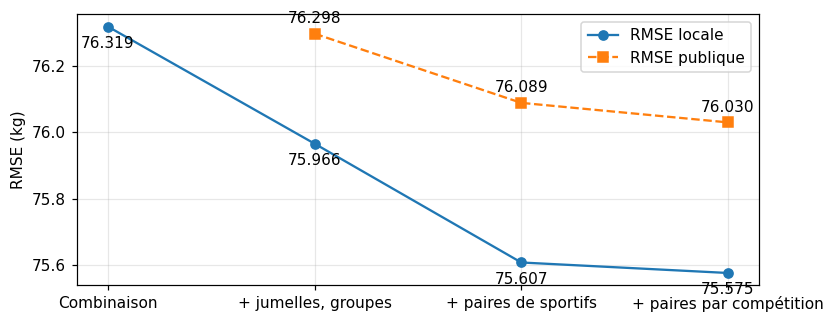

In [16]:
def show_pair_smoothing():
    # Recalculer le score après chaque correction à partir des prédictions sauvegardées, sans entraînement.
    eight = ARTIFACTS / '04_final_model' / CACHE_FINAL_ENSEMBLE
    pairs = ARTIFACTS / '04_final_model' / 'v5_pair_smoothing'
    steps = [('Combinaison des huit modèles', eight / 'oof_nested_blend.npy', np.nan),
             ('+ jumelles et lissage par groupes (exp. 15)', eight / 'oof_final_crossfit.npy', 76.298),
             ('+ paires de sportifs (exp. 16)', pairs / 'oof_v5_A_pair.npy', 76.089),
             ('+ paires dans la compétition (exp. 17, finale)', pairs / 'oof_v5_H_meet_ridge.npy', 76.030)]
    if not all(path.is_file() for _, path, _ in steps):
        print('Résultats du lissage par paires absents : récupérer artifacts/ ou activer pair_smoothing')
        return
    rows, previous = [], None
    for name, path, public in steps:
        oof = np.load(path)
        row = {'Étape': name, 'RMSE locale': rmse(y, oof), 'RMSE publique': public}
        if previous is not None:
            row['Écart avec l’étape précédente'] = rmse(y, oof) - rmse(y, previous)
            row['Plis améliorés'] = sum(rmse(y[FOLD_IDS == k], oof[FOLD_IDS == k]) < rmse(y[FOLD_IDS == k], previous[FOLD_IDS == k])
                                        for k in range(1, N_FOLDS + 1))
        rows.append(row)
        previous = oof
    table = pd.DataFrame(rows).set_index('Étape')
    display(table.round(3))

    fig, ax = plt.subplots(figsize=(8, 3.2))
    x = np.arange(len(table))
    ax.plot(x, table['RMSE locale'], marker='o', label='RMSE locale')
    ax.plot(x, table['RMSE publique'], marker='s', linestyle='--', label='RMSE publique')
    for i, (local, public) in enumerate(zip(table['RMSE locale'], table['RMSE publique'])):
        ax.annotate(f'{local:.3f}', (i, local), xytext=(0, -14), textcoords='offset points', ha='center')
        if np.isfinite(public):
            ax.annotate(f'{public:.3f}', (i, public), xytext=(0, 7), textcoords='offset points', ha='center')
    ax.set_xticks(x, ['Combinaison', '+ jumelles, groupes', '+ paires de sportifs', '+ paires par compétition'])
    ax.set_ylabel('RMSE (kg)')
    ax.legend()
    plt.show()


show_pair_smoothing()

Le lissage par paires de sportifs fait passer le score local de 75.966 à **75.607** (−0.359), sur les 5 plis et les 2 moitiés, et le score public de 76.298 à 76.089. Le second passage ajoute −0.032 en local (**75.575**) et donne 76.030 au public. C'est juste au-dessus du seuil de 0.03 qu'on s'était fixé avant de le lancer, donc on s'arrête là.

Variantes essayées sans gain (détail dans `RESULTS.md`) : paires avec un État inconnu d'un seul côté, ridge au premier passage, 600 itérations au lieu de 300, lissage par paires sans les statistiques de groupes.

## 6. Fichiers de soumission et score public

Le score public porte sur environ 30 % du test (13 500 lignes). Un écart de moins de 0.05 kg entre deux soumissions ne veut pas dire grand-chose (voir la simulation du notebook 05).

In [17]:
final_file = ARTIFACTS / '04_final_model' / 'v5_pair_smoothing' / 'submission_v5_H_meet_ridge.csv'
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
if final_file.is_file():
    final_sub = pd.read_csv(final_file)
    require(final_sub.columns.tolist() == ['id', TARGET], 'Colonnes attendues : id, TotalKg')
    require(len(final_sub) == len(sample_submission) == 45000 and final_sub['id'].is_unique
            and set(final_sub['id']) == set(sample_submission['id']), 'Les id diffèrent de sample_submission')
    require(np.isfinite(final_sub[TARGET]).all() and (final_sub[TARGET] > 0).all(), 'Valeurs de prédiction invalides')
    print(f'Contrôles OK : {final_file.relative_to(PROJECT_DIR)}, {len(final_sub)} lignes ; moyenne {final_sub[TARGET].mean():.1f}, '
          f'étendue {final_sub[TARGET].min():.1f}–{final_sub[TARGET].max():.1f} (moyenne train {y.mean():.1f})')
else:
    print(f'Fichier absent : {final_file.relative_to(PROJECT_DIR)}')

leaderboard = pd.DataFrame([
    ('11', '6 modèles × 3 graines, moyenne des modèles de plis, jumelles et lissage', 76.044, 76.520),
    ('11', 'Les mêmes, arbres réentraînés sur toutes les lignes', np.nan, 76.360),
    ('12', 'Réentraînement avec 8 graines', np.nan, 76.359),
    ('12', '+ TabM sur 95 % × 3 graines', np.nan, 76.337),
    ('13', '+ HGB', 76.010, 76.334),
    ('15', '8 modèles (CatBoost IPF GL et HGB sur 3 graines, TabM sur 5)', 75.966, 76.298),
    ('16', '+ lissage par paires de sportifs', 75.607, 76.089),
    ('17', '+ lissage par paires dans la compétition (finale)', 75.575, 76.030),
], columns=['Expérience', 'Soumission', 'RMSE locale', 'RMSE publique'])
display(leaderboard.set_index('Expérience'))

Contrôles OK : artifacts/04_final_model/v5_pair_smoothing/submission_v5_H_meet_ridge.csv, 45000 lignes ; moyenne 495.7, étendue 75.7–1186.2 (moyenne train 493.0)


,Soumission,RMSE locale,RMSE publique
Expérience,,,
11,"6 modèles × 3 graines, moyenne des modèles de ...",76.044,76.520
11,"Les mêmes, arbres réentraînés sur toutes les l...",NaN,76.360
12,Réentraînement avec 8 graines,NaN,76.359
12,+ TabM sur 95 % × 3 graines,NaN,76.337
13,+ HGB,76.010,76.334
15,8 modèles (CatBoost IPF GL et HGB sur 3 graine...,75.966,76.298
16,+ lissage par paires de sportifs,75.607,76.089
17,+ lissage par paires dans la compétition (finale),75.575,76.030


Fichiers gardés dans `submissions/` :

1. `20261110_v6_meet_smoothing.csv` : soumission finale, meilleur score local et public (75.575 / 76.030) ;
2. `20261017_FINAL_v4_eight_models.csv` : la version sans lissage par paires (75.966 / 76.298).

Les deux passages du lissage par paires gagnent 0.391 kg en local et 0.268 kg au public : même sens, mais moins au public.